<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-13/lab-074-state-tomography.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 074. Quantum state tomography

A quantum device that is meant to prepare a Bell pair returns only bit strings, run after run. Each run destroys the state, and one bit string says almost nothing about it. To find out which state the device prepares, we repeat the preparation many times, rotate the measurement basis between runs and reconstruct the density matrix from the recorded frequencies. This reconstruction is called quantum state tomography [1,2]. Its result is a complete description of the prepared state, from which every expectation value, the fidelity with the intended state and the entanglement follow.

We work with two qubits and three states that a two-qubit device may prepare, namely the Bell state, a Werner state, which is a Bell state mixed with white noise, and a randomly drawn mixed state. We are given a source that prepares the unknown state on demand, single-qubit gates that rotate each qubit before a measurement in the computational basis, and a budget of $M$ shots per measurement setting. We estimate the density matrix in three ways, by linear inversion of the Born rule, by projecting the linear-inversion estimate onto the set of physical states and by maximising the likelihood of the data. We then measure how the error of each estimate decreases with $M$. The sketch places tomography among the questions that measured bit strings can answer.

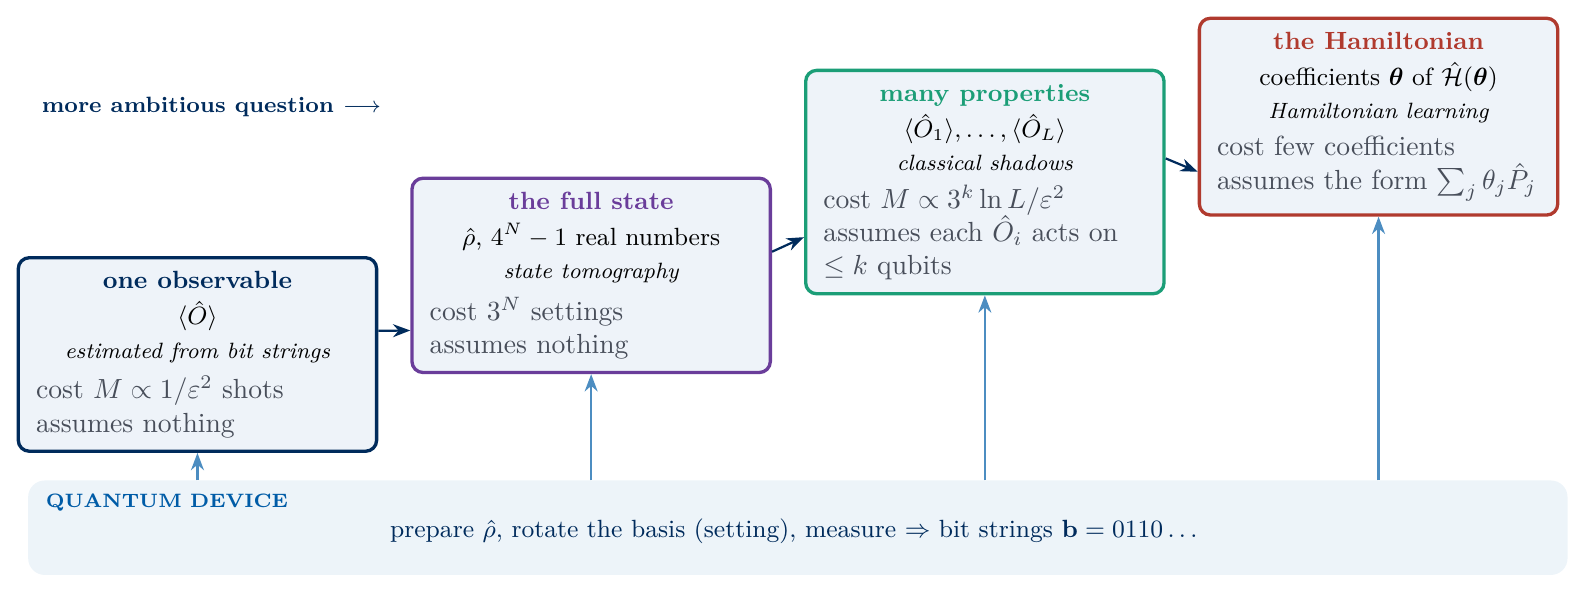

*Questions of increasing ambition answered from the same bit strings, with their cost and assumptions. Tomography reconstructs the full state and assumes nothing about it. The boxes on many properties and on the Hamiltonian use classical shadows and Hamiltonian learning, the subjects of Labs 075 and 077.*

Section 2 defines the density matrix, the three test states and three measures of the distance between states. Section 3 reconstructs one qubit from three measurement settings. Sections 4 to 6 extend this to two qubits with Pauli strings, a simulated experiment and the linear model that connects the density matrix to the frequencies. Section 7 shows that the linear estimate is often unphysical, and Section 8 projects it onto the physical states. Section 9 introduces maximum-likelihood estimation with two algorithms, and Section 10 measures the error of all estimators as a function of the number of shots. Sections 1 to 10 form the core route, and Section 11, for work at home, counts how the cost of tomography grows with the number of qubits.

Quantities called exact come from the density matrix, which the simulation knows and the experimenter does not. Estimates come from simulated measurement records with fixed random seeds, in the form a device returns them. Lab 076 uses the three estimators of this lab again, as the starting point and the reference of neural-network tomography.

The notebook runs in 60 to 80 seconds on a CPU. The slowest cells are the check with Haar-random states in Section 10, ten to fifteen seconds, the sampling of the 3600 data sets in Section 7, about ten seconds, the shot scan of Section 10 and the cost count of Section 11, about eight seconds each, and the sampler test of Section 5 and the two maximum-likelihood algorithms of Section 9, about five seconds each.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, so that identities hold to about $10^{-12}$. NumPy handles the $4\times4$ matrices, JAX draws the random shots and differentiates the likelihood on the CPU, and Matplotlib draws the figures. The cells run in order.

The code uses three JAX constructs beyond `jax.grad`, `jax.jit` and `jax.vmap`. JAX arrays cannot be changed in place, so `x.at[idx].set(v)` and `x.at[idx].add(v)` return a new array in which the entries at `idx` are replaced by `v` or increased by `v`. The option `static_argnums` of `jax.jit` names the arguments that the compiled function treats as fixed Python numbers, here the number of shots or of iterations, which set array shapes and loop lengths, and the function is compiled again for every new value of such an argument. The function `jax.lax.scan(step, init, xs)` is a compiled for-loop. It starts from `carry = init`, calls `carry, y = step(carry, x)` for every element `x` of `xs` and returns the final `carry` together with the array of all recorded values `y`. With `xs=None` and `length=n` it runs `n` steps without an input.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # small calculations; the CPU avoids GPU memory allocation
import json, time, itertools
from functools import partial, reduce
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
# course palette for estimators: linear inversion grey, projection green, maximum likelihood orange, true state black;
# other series: navy, purple, teal
COL = dict(li="#9AA0A6", proj="#1B7F36", mle="#D35A05", exact="black", grey="#5A6270", rand="#9AA0A6",
           navy="#002B5C", purple="#6A3D9A", teal="#1B9E77")
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}
def panels(name, draws, label_xy=None, width_ratios=None):
    # notes: all panels side by side, 7.0 x 2.9 in, 11 pt; slides: every panel alone as name_a, name_b, ... at 4.6 x 3.1 in, 12-13 pt
    n = len(draws)
    label_xy = label_xy or [(0.03, 0.96, "top")] * n
    fig, axes = plt.subplots(1, n, figsize=(7.0, 2.9), gridspec_kw={"width_ratios": width_ratios} if width_ratios else None)
    for i, (ax, draw) in enumerate(zip(axes, draws)):
        draw(ax)
        ax.text(label_xy[i][0], label_xy[i][1], f"({'abc'[i]})", transform=ax.transAxes, va=label_xy[i][2])
    fig.tight_layout(); save(fig, name); plt.show()
    with plt.rc_context(SLIDE_RC):
        for i, draw in enumerate(draws):
            f1, a1 = plt.subplots(figsize=(4.6, 3.1)); draw(a1); f1.tight_layout(); save(f1, f"{name}_{'abc'[i]}"); plt.close(f1)
def single(name, draw):
    fig, ax = plt.subplots(figsize=(4.6, 3.1)); draw(ax); fig.tight_layout(); save(fig, name); plt.show()
started = time.perf_counter()
NUMBERS = {}
def sci(x, digits=1):
    # LaTeX form of a number in scientific notation for the macro file, e.g. 1.1\times10^{5} (used in math mode)
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
WORD = {20: "Twenty", 200: "TwoHundred", 2000: "TwoThousand"}   # macro names cannot contain digits
key = jax.random.PRNGKey(74)
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Density matrices and the distance between states

A device that prepares a pure state $|\psi\rangle$ in every run is described by the projector $|\psi\rangle\langle\psi|$. A real device fluctuates and prepares $|\psi_a\rangle$ with probability $w_a$, and all predictions are then contained in the density matrix $\hat\rho=\sum_a w_a|\psi_a\rangle\langle\psi_a|$. For two qubits it is a $4\times4$ Hermitian matrix with unit trace and non-negative eigenvalues, and these three properties define a physical state. Its purity $\mathrm{Tr}\,\hat\rho^2$ equals one for a pure state and $1/4$ for the maximally mixed state $\hat I/4$. A measurement with outcomes $\mathbf b$ is described by projectors $\hat\pi_{\mathbf b}$ that sum to the identity, and the Born rule gives the probability of outcome $\mathbf b$ as
$$p(\mathbf b)=\mathrm{Tr}\big[\hat\rho\,\hat\pi_{\mathbf b}\big] . \tag{1}$$
Tomography inverts this relation and recovers $\hat\rho$ from estimated probabilities.

Our three test states are the Bell state $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$, a pure entangled state, the Werner state $\hat\rho_W=v\,|\Phi^+\rangle\langle\Phi^+|+(1-v)\,\hat I/4$ with visibility $v=0.8$ [3], which is entangled for $v>1/3$ [4,5], and a random mixed state $\hat\rho_{\mathrm{rand}}=GG^\dagger/\mathrm{Tr}(GG^\dagger)$, where $G$ is a $4\times4$ matrix of independent complex Gaussian entries. The last construction draws states uniformly with respect to the Hilbert–Schmidt measure [6], and the drawn state has four distinct eigenvalues and no symmetry between the two qubits.

To judge an estimate $\tilde\rho$ we need distances to the true state $\hat\rho$. The fidelity
$$F(\hat\rho,\tilde\rho)=\Big(\mathrm{Tr}\sqrt{\sqrt{\hat\rho}\,\tilde\rho\,\sqrt{\hat\rho}}\Big)^2 \tag{2}$$
equals one for identical states, where the square root of a positive semidefinite matrix keeps the eigenvectors and takes the square root of every eigenvalue. It reduces to $\langle\psi|\tilde\rho|\psi\rangle$ when $\hat\rho=|\psi\rangle\langle\psi|$ is pure [7,8]. The trace distance
$$D(\hat\rho,\tilde\rho)=\tfrac12\,\big\|\hat\rho-\tilde\rho\big\|_1=\tfrac12\sum_i|\lambda_i| , \tag{3}$$
where $\lambda_i$ are the eigenvalues of $\hat\rho-\tilde\rho$, is the largest difference between the probabilities that the two states assign to any measurement outcome [9]. The Hilbert–Schmidt distance
$$D_{\mathrm{HS}}(\hat\rho,\tilde\rho)=\sqrt{\mathrm{Tr}\big[(\hat\rho-\tilde\rho)^2\big]} \tag{4}$$
is the Euclidean distance between the two matrices viewed as vectors of their entries. For one qubit all three quantities follow from the Bloch vectors of the two states, as the sketch shows.

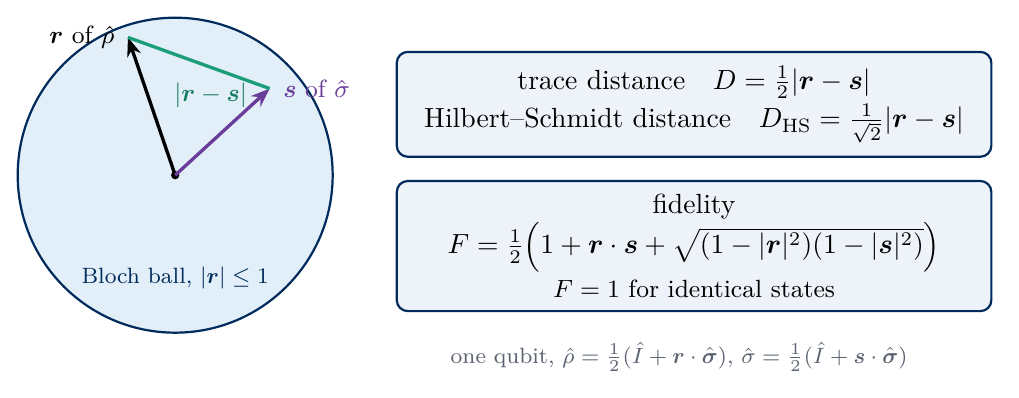

*Trace distance, Hilbert–Schmidt distance and fidelity of two one-qubit states with Bloch vectors $\boldsymbol r$ and $\boldsymbol s$. Both distances are proportional to $|\boldsymbol r-\boldsymbol s|$, whereas the fidelity also depends on the lengths of the two vectors.*

The code builds the three states, checks the defining properties and evaluates equations (2) to (4) for the Bell and Werner states, for which $F=v+(1-v)/4$ and $D=\tfrac34(1-v)$.

Bell   : eigenvalues [0. 0. 0. 1.], purity 1.000
Werner : eigenvalues [0.05 0.05 0.05 0.85], purity 0.730
random : eigenvalues [0.049 0.089 0.3   0.562], purity 0.416
Bell vs Werner: F = 0.850, D = 0.150, D_HS = 0.173


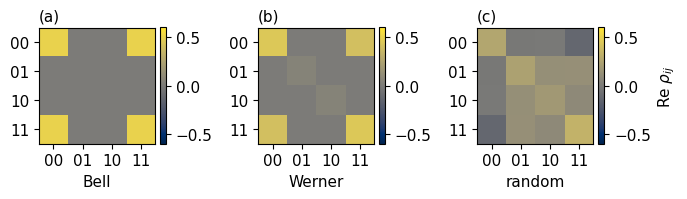

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
PAULI = {"I": I2, "X": X, "Y": Y, "Z": Z}
N, d = 2, 4                                          # qubits and Hilbert-space dimension; qubit 0 is the leftmost factor

phi_plus = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)
rho_bell = np.outer(phi_plus, phi_plus.conj())
v_W = 0.8                                            # visibility of the Werner state
rho_werner = v_W * rho_bell + (1 - v_W) * np.eye(d) / d
rng_state = np.random.default_rng(22)               # fixed seed of the random mixed state
G = rng_state.normal(size=(d, d)) + 1j * rng_state.normal(size=(d, d))
rho_rand = G @ G.conj().T / np.trace(G @ G.conj().T).real
STATES = {"Bell": rho_bell, "Werner": rho_werner, "random": rho_rand}

def sqrtm_psd(rho):
    # square root of a positive semidefinite matrix (or a stack) from its eigendecomposition
    w, v = np.linalg.eigh(rho)
    return (v * np.sqrt(np.clip(w, 0, None))[..., None, :]) @ v.conj().swapaxes(-1, -2)

def fidelity(rho, sigma):
    # equation (2); rho is the true state, sigma one estimate or a stack of estimates
    w, v = np.linalg.eigh(rho)
    if w[-1] > 1 - 1e-12:                                 # pure true state: F = <psi|sigma|psi>
        return np.real(np.einsum("i,...ij,j->...", v[:, -1].conj(), sigma, v[:, -1]))
    s = sqrtm_psd(rho)
    return np.sum(np.sqrt(np.clip(np.linalg.eigvalsh(s @ sigma @ s), 0, None)), axis=-1) ** 2

def trace_distance(rho, sigma):
    return 0.5 * np.sum(np.abs(np.linalg.eigvalsh(sigma - rho)), axis=-1)       # equation (3)

def hs_distance(rho, sigma):
    return np.sqrt(np.sum(np.abs(sigma - rho) ** 2, axis=(-2, -1)))             # equation (4)

for name, rho in STATES.items():
    ev = np.linalg.eigvalsh(rho)
    assert np.allclose(rho, rho.conj().T) and abs(np.trace(rho) - 1) < TOL and ev.min() > -TOL
    assert abs(fidelity(rho, rho) - 1) < 1e-10
    print(f"{name:7s}: eigenvalues {np.round(ev, 3)}, purity {np.trace(rho @ rho).real:.3f}")
F_bw, D_bw = fidelity(rho_bell, rho_werner), trace_distance(rho_bell, rho_werner)
assert abs(F_bw - (v_W + (1 - v_W) / 4)) < 1e-10 and abs(D_bw - 0.75 * (1 - v_W)) < TOL
assert abs(fidelity(rho_bell, rho_rand) - np.real(phi_plus.conj() @ rho_rand @ phi_plus)) < 1e-10
assert abs(fidelity(rho_rand, rho_werner) - fidelity(rho_werner, rho_rand)) < 1e-10      # F is symmetric
print(f"Bell vs Werner: F = {F_bw:.3f}, D = {D_bw:.3f}, D_HS = {hs_distance(rho_bell, rho_werner):.3f}")
NUMBERS.update(PWerner=f"{v_W}", RandMinEig=f"{np.linalg.eigvalsh(rho_rand)[0]:.3f}")

ticks = ["00", "01", "10", "11"]
def state_panel(name, rho):
    def draw(ax):
        im = ax.imshow(rho.real, cmap="cividis", vmin=-0.6, vmax=0.6)
        ax.set_xticks(range(4)); ax.set_xticklabels(ticks); ax.set_yticks(range(4)); ax.set_yticklabels(ticks)
        ax.set_xlabel(name)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=r"Re $\rho_{ij}$" if name == "random" else None)
    return draw
panels("fig_lab074_states", [state_panel(nm, r) for nm, r in STATES.items()], label_xy=[(0.0, 1.03, "bottom")] * 3)

The figure shows the real parts of the three density matrices in the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$. The Bell state has four equal entries in the corners, the populations of $|00\rangle$ and $|11\rangle$ and the coherence between them. The Werner state keeps the same pattern with reduced coherence and adds a uniform background on the diagonal. The random state has nonzero entries everywhere and an imaginary part that the figure does not show. Tomography has to recover such a matrix from bit strings.

## 3. One qubit from three settings

Every one-qubit density matrix can be written as
$$\hat\rho=\tfrac12\big(\hat I+r_x\hat X+r_y\hat Y+r_z\hat Z\big),\qquad r_P=\langle\hat P\rangle=\mathrm{Tr}(\hat\rho\hat P) , \tag{5}$$
because the four matrices $\hat I,\hat X,\hat Y,\hat Z$ form a basis of the $2\times2$ matrices and are orthogonal, $\mathrm{Tr}(\hat P\hat P')=2\delta_{PP'}$. The Bloch vector $\boldsymbol r=(r_x,r_y,r_z)$ lies inside the unit ball, $|\boldsymbol r|\le1$, which is the condition that the eigenvalues $(1\pm|\boldsymbol r|)/2$ are non-negative, and pure states lie on its surface.

A device measures only in the computational basis, which gives $r_z$. To measure $\hat X$ we apply the Hadamard gate $\hat H$ before the measurement, and to measure $\hat Y$ we apply $\hat S^\dagger$ and then $\hat H$, with the phase gate $\hat S=\mathrm{diag}(1,i)$. With the rotation $\hat u_P$ of the setting, $\hat u_X=\hat H$, $\hat u_Y=\hat H\hat S^\dagger$ and $\hat u_Z=\hat I$, one has $\hat u_P^\dagger\hat Z\hat u_P=\hat P$, so bit $0$ signals the eigenvalue $+1$ of $\hat P$ and bit $1$ the eigenvalue $-1$. The probability of bit 1 is $(1-r_P)/2$. After $M$ shots in setting $P$, with $n_0$ outcomes 0 and $n_1=M-n_0$ outcomes 1, the estimate and its variance are
$$\tilde r_P=\frac{n_0-n_1}{M}=1-\frac{2n_1}{M},\qquad \mathrm{Var}(\tilde r_P)=\frac{1-r_P^2}{M} , \tag{6}$$
since every shot gives an independent value $\pm1$ with mean $r_P$ and variance $1-r_P^2$. Three settings, $3M$ shots in total and drawn in the sketch, determine the full state.

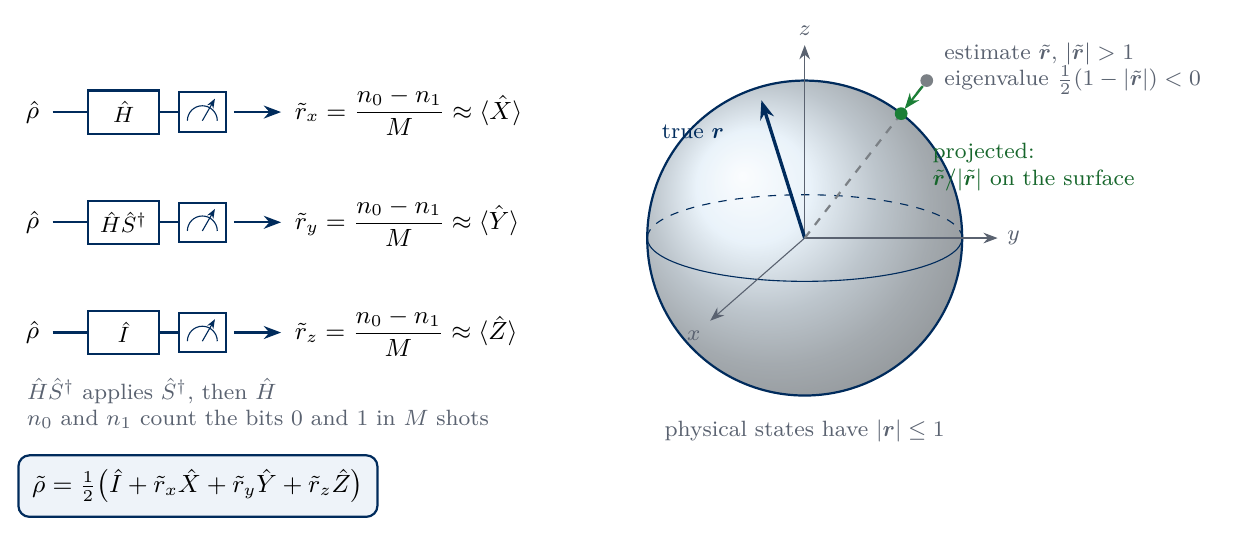

*Three measurement settings of one qubit, each giving one component of the Bloch vector from the counts $n_0$ and $n_1$. An estimate outside the unit ball has a negative eigenvalue, and the closest physical state is the unit vector in the same direction.*

The code repeats this experiment 2000 times for a mixed state with $\boldsymbol r=(0.54,0,0.72)$, $|\boldsymbol r|=0.9$, and $M=50$ shots per setting, compares the spread of the estimates with equation (6) and counts how often the estimated Bloch vector leaves the unit ball.

variance of the estimates (x, y, z): [0.0136 0.0198 0.0096]  equation (6): [0.0142 0.02   0.0096]
estimated Bloch vectors outside the unit ball: 23.0% of 2000 runs


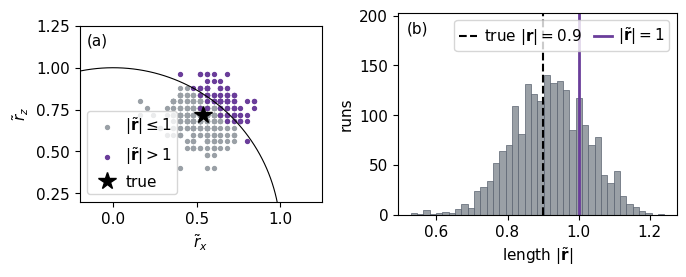

In [3]:
HAD = (X + Z) / np.sqrt(2)                           # Hadamard gate
SDG = np.diag([1, -1j])                              # S^dagger
BASIS_ROT = {"X": HAD, "Y": HAD @ SDG, "Z": I2}      # u_P, applied before the measurement in the computational basis
for P, u in BASIS_ROT.items():
    assert np.allclose(u.conj().T @ Z @ u, PAULI[P])  # measuring Z after u_P measures P

r_true = np.array([0.54, 0.0, 0.72])
rho_q = 0.5 * (I2 + sum(r * PAULI[P] for r, P in zip(r_true, "XYZ")))
p_one = np.array([np.real((BASIS_ROT[P] @ rho_q @ BASIS_ROT[P].conj().T)[1, 1]) for P in "XYZ"])
assert np.allclose(p_one, (1 - r_true) / 2)          # probability of bit 1 in setting P

M_Q, R_Q = 50, 2000
key, k = jax.random.split(key)
n_one = np.asarray(jax.random.bernoulli(k, jnp.asarray(p_one), shape=(R_Q, M_Q, 3)).sum(axis=1))
r_est = 1 - 2 * n_one / M_Q                          # equation (6), shape (R_Q, 3)
var_pred = (1 - r_true ** 2) / M_Q
var_meas = r_est.var(axis=0, ddof=1)
assert np.all(np.abs(var_meas / var_pred - 1) < 0.15)   # relative error of a variance from 2000 runs is about 3 %
outside = np.linalg.norm(r_est, axis=1) > 1
print("variance of the estimates (x, y, z):", np.round(var_meas, 4), " equation (6):", np.round(var_pred, 4))
print(f"estimated Bloch vectors outside the unit ball: {outside.mean():.1%} of {R_Q} runs")
NUMBERS.update(BlochOutside=f"{100 * outside.mean():.0f}", BlochShots=f"{M_Q}")

show = slice(0, 400)
def bloch_plane(ax):
    t = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(t), np.sin(t), color=COL["exact"], lw=0.8)
    ax.scatter(r_est[show][~outside[show], 0], r_est[show][~outside[show], 2], s=8, color=COL["li"], label=r"$|\tilde{\mathbf{r}}|\leq1$")
    ax.scatter(r_est[show][outside[show], 0], r_est[show][outside[show], 2], s=8, color=COL["purple"], label=r"$|\tilde{\mathbf{r}}|>1$")
    ax.plot(r_true[0], r_true[2], "*", ms=13, color=COL["exact"], label="true")
    ax.set_xlim(-0.2, 1.25); ax.set_ylim(0.2, 1.25); ax.set_aspect("equal")
    ax.set_xlabel(r"$\tilde r_x$"); ax.set_ylabel(r"$\tilde r_z$"); ax.legend(loc="lower left", handletextpad=0.2, borderpad=0.3)
def bloch_length(ax):
    counts_len = ax.hist(np.linalg.norm(r_est, axis=1), bins=40, color=COL["li"], edgecolor=COL["grey"], lw=0.5)[0]
    ax.axvline(np.linalg.norm(r_true), color=COL["exact"], ls="--", lw=1.5, label=r"true $|\mathbf{r}|=0.9$")
    ax.axvline(1, color=COL["purple"], lw=2, label=r"$|\tilde{\mathbf{r}}|=1$")
    ax.set_ylim(0, 1.45 * counts_len.max())
    ax.set_xlabel(r"length $|\tilde{\mathbf{r}}|$"); ax.set_ylabel("runs")
    ax.legend(loc="upper right", ncol=2, handlelength=1.2, columnspacing=0.8, handletextpad=0.4, borderpad=0.3)
panels("fig_lab074_bloch", [bloch_plane, bloch_length], label_xy=[(0.03, 0.96, "top"), (0.03, 0.96, "top")], width_ratios=[1, 1.15])

Panel (a) shows 400 of the estimated Bloch vectors projected on the $xz$ plane, with the true vector as a star and the unit circle as the boundary of the physical states. The estimates scatter around the true vector with the spread of equation (6). With $M=50$ every component takes one of the values $1-2n_1/50$, so the estimates lie on a grid of spacing $0.04$ and many of the 400 points coincide. The colour marks the full length $|\tilde{\boldsymbol r}|$, which includes the component $\tilde r_y$ hidden by the projection, so some purple points with $|\tilde{\boldsymbol r}|>1$ appear inside the circle. Panel (b) shows the length of the estimated vectors in all 2000 runs, with the true length $0.9$ as the dashed line and the surface of the Bloch ball, $|\tilde{\boldsymbol r}|=1$, as the purple line. The length exceeds one in a sizeable fraction of the runs, the bars to the right of the purple line. Such an estimate has a negative eigenvalue $(1-|\tilde{\boldsymbol r}|)/2$ and is no density matrix. The direct estimate is unbiased, since the mean of each component equals the true one, but it ignores the constraint $|\boldsymbol r|\le1$. This problem grows when the state is close to pure and returns for two qubits in Section 7.

## 4. Pauli strings and informational completeness

For $N$ qubits the role of $\hat I,\hat X,\hat Y,\hat Z$ is taken by the $4^N$ Pauli strings $\hat P=\hat\sigma_{p_0}\otimes\hat\sigma_{p_1}\otimes\dots\otimes\hat\sigma_{p_{N-1}}$ with letters $p_q\in\{I,X,Y,Z\}$, qubit 0 being the leftmost factor. They are orthogonal, $\mathrm{Tr}(\hat P\hat P')=2^N\delta_{PP'}$, so every density matrix has the expansion
$$\hat\rho=\frac{1}{2^N}\sum_{P}\langle\hat P\rangle\,\hat P , \tag{7}$$
which generalises equation (5). The coefficient of the identity string is one by normalisation, so $4^N-1$ real numbers, 15 for two qubits, have to be measured. The number of non-identity letters of $\hat P$ is its weight $k$. A measurement setting $s=(s_0,\dots,s_{N-1})$ with $s_q\in\{X,Y,Z\}$ rotates every qubit with $\hat u_{s_q}$ and measures all of them, and there are $3^N$ settings. One setting gives the expectation value of every Pauli string whose letters agree with $s$ on its support, the qubits on which the string carries a letter other than $I$, because the product of the $\pm1$ values of the qubits on the support is the eigenvalue of the string. The string $\hat X\hat I$, for example, is measured by the settings $XX$, $XY$ and $XZ$, and in general a string of weight $k$ is measured by $3^{N-k}$ settings. The settings together determine all $4^N$ expectation values, and a measurement with this property is called informationally complete. For one qubit a single measurement with four outcomes, whose Bloch vectors point to the corners of a tetrahedron, is informationally complete as well.

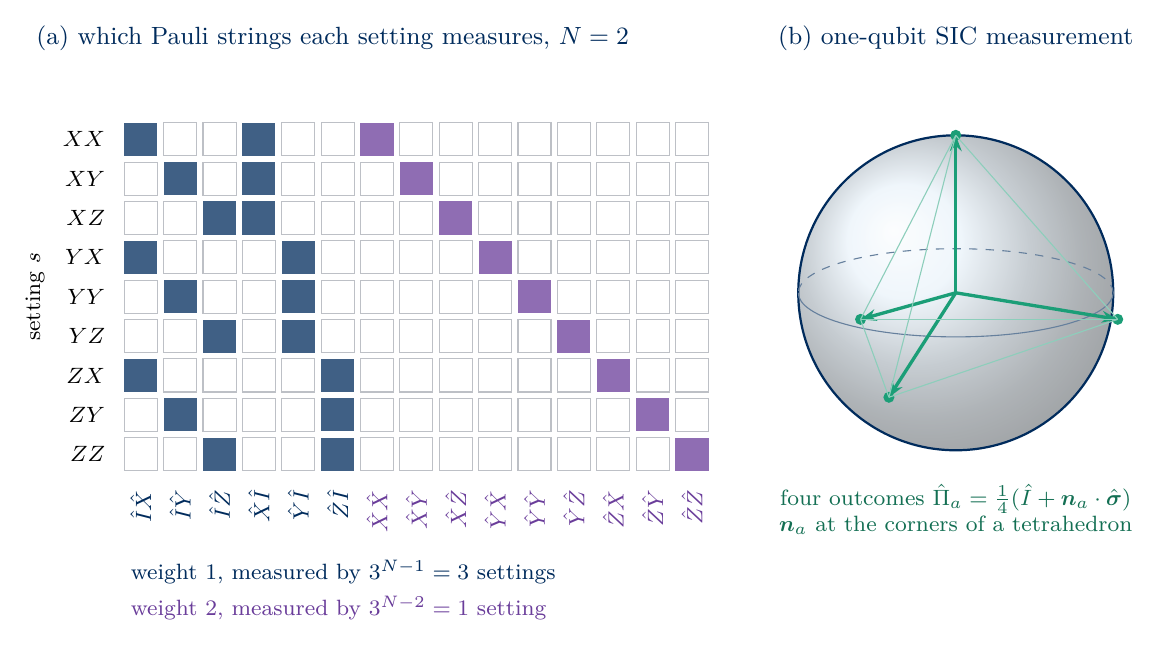

*(a) The Pauli strings measured by each of the nine settings of two qubits. A weight-one string is measured by three settings and a weight-two string by one. (b) The one-qubit measurement with four outcomes at the corners of a tetrahedron.*

The code builds the 16 Pauli strings of two qubits, checks their orthogonality and the round trip $\hat\rho\to\langle\hat P\rangle\to\hat\rho$ of equation (7).

In [4]:
def kron_all(mats):
    return reduce(np.kron, mats)

def pauli_labels(n):
    return ["".join(p) for p in itertools.product("IXYZ", repeat=n)]

def pauli_matrices(n):
    return np.array([kron_all([PAULI[c] for c in lab]) for lab in pauli_labels(n)])

LABELS = pauli_labels(N)
PAULIS = pauli_matrices(N)                                     # (16, 4, 4)
WEIGHT = np.array([sum(c != "I" for c in lab) for lab in LABELS])

def pauli_vector(rho):
    return np.real(np.einsum("pij,...ji->...p", PAULIS, rho))  # <P> = Tr(rho P) for all 16 strings

def rho_from_pauli(r):
    return np.einsum("...p,pij->...ij", r, PAULIS) / d         # equation (7)

gram = np.real(np.einsum("pij,qji->pq", PAULIS, PAULIS))
assert np.allclose(gram, d * np.eye(4 ** N))
for name, rho in STATES.items():
    assert np.allclose(rho_from_pauli(pauli_vector(rho)), rho, atol=TOL)
r_bell = pauli_vector(rho_bell)
print("nonzero Pauli expectation values of the Bell state:",
      {lab: round(float(v), 6) for lab, v in zip(LABELS, r_bell) if abs(v) > TOL})
print("number of strings of weight 0, 1, 2:", np.bincount(WEIGHT))

nonzero Pauli expectation values of the Bell state: {'II': 1.0, 'XX': 1.0, 'YY': -1.0, 'ZZ': 1.0}
number of strings of weight 0, 1, 2: [1 6 9]


The Bell state has only four nonzero expectation values, $\langle\hat I\hat I\rangle=\langle\hat X\hat X\rangle=\langle\hat Z\hat Z\rangle=1$ and $\langle\hat Y\hat Y\rangle=-1$, and all its single-qubit expectation values vanish, as for any maximally entangled state. The six strings of weight one and the nine of weight two together with the identity give the 16 coefficients.

## 5. The simulated experiment

The measurement of setting $s$ with outcome bit string $\mathbf b=b_0b_1\dots b_{N-1}$ corresponds to the projector
$$\hat\pi_{s,\mathbf b}=\hat U_s^\dagger|\mathbf b\rangle\langle\mathbf b|\hat U_s=\bigotimes_{q=0}^{N-1}\frac{\hat I+(-1)^{b_q}\hat\sigma_{s_q}}{2},\qquad \hat U_s=\hat u_{s_0}\otimes\dots\otimes\hat u_{s_{N-1}} , \tag{8}$$
and by equation (1) its probability is $p_s(\mathbf b)=\mathrm{Tr}[\hat\rho\,\hat\pi_{s,\mathbf b}]=\langle\mathbf b|\hat U_s\hat\rho\,\hat U_s^\dagger|\mathbf b\rangle$, the diagonal of the rotated density matrix. The bit string $\mathbf b$ is the binary form of the outcome index $i=\sum_q b_q2^{N-1-q}$, with qubit 0 as the most significant bit. For each setting the device returns $M$ bit strings, and the data are the counts $n_s(\mathbf b)$ with frequencies $f_s(\mathbf b)=n_s(\mathbf b)/M$.

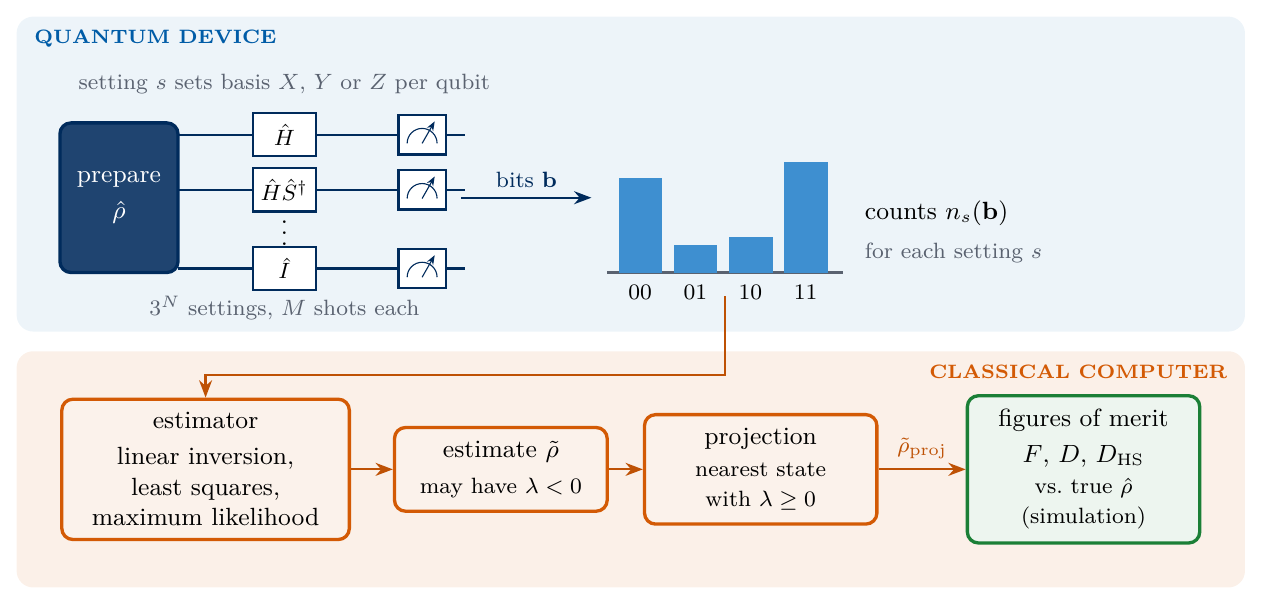

*Tomography from the device to the figures of merit. The device rotates every qubit into the basis of setting $s$ and returns $M$ bit strings per setting. The classical computer turns the counts into an estimate, projects it onto the physical states when an eigenvalue is negative and, in a simulation, compares it with the true state.*

The simulator rotates the density matrix, reads the diagonal and draws $M$ outcomes from it with `jax.random.categorical`, one call per setting under `jax.vmap`. Before using it, we test that the probabilities agree with the product formula (8) and that the sampled counts follow the multinomial distribution. For the second test we use Pearson's statistic $\chi^2=\sum_{\mathbf b}[n_s(\mathbf b)-Mp_s(\mathbf b)]^2/[Mp_s(\mathbf b)]$, summed over the settings, [10], whose mean over many data sets equals the number of degrees of freedom. Four counts that must sum to $M$ leave three free, which gives three degrees of freedom per setting and 27 for the nine settings. As a control, a sampler with a common bit-order error, qubit 0 read as the least significant bit, must fail the same test. The control uses the random state, since the Bell and Werner states are symmetric under the exchange of the two qubits and would hide this error.

mean chi^2 over 100 data sets: 26.4  (expected 27 +- 0.7)
control with reversed bit order: mean chi^2 = 2709  -> detected


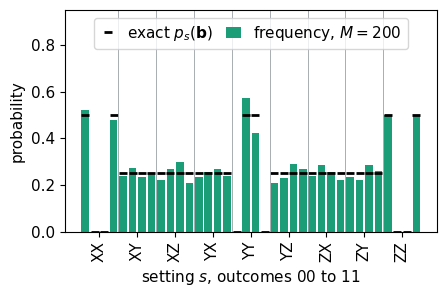

In [5]:
SETTINGS = ["".join(s) for s in itertools.product("XYZ", repeat=N)]
def setting_unitaries(n):
    return np.array([kron_all([BASIS_ROT[c] for c in s]) for s in itertools.product("XYZ", repeat=n)])
U_SET = setting_unitaries(N)                                     # (9, 4, 4)
PROJ = np.einsum("sbi,sbj->sbij", U_SET.conj(), U_SET)           # pi_{b|s}[i, j] = conj(U[b, i]) U[b, j], equation (8)

def born_table(rho):
    return np.real(np.einsum("sbi,ij,sbj->sb", U_SET, rho, U_SET.conj()))   # p_s(\mathbf b), shape (9, 4)

def bits_of(i, n):
    return [(i >> (n - 1 - q)) & 1 for q in range(n)]            # qubit 0 = most significant bit

for s, name in enumerate(SETTINGS):                              # equation (8) as a product of one-qubit projectors
    for b in range(d):
        prod = kron_all([(I2 + (-1) ** bq * PAULI[c]) / 2 for bq, c in zip(bits_of(b, N), name)])
        assert np.allclose(PROJ[s, b], prod)
for rho in STATES.values():
    assert np.allclose(born_table(rho), np.real(np.einsum("sbij,ji->sb", PROJ, rho)))
    assert np.allclose(born_table(rho).sum(axis=1), 1)

@partial(jax.jit, static_argnums=2)
def sample_counts(key, probs, shots):
    # probs (S, d) -> counts (S, d): `shots` categorical draws per setting, settings handled by vmap
    def one(k, p):
        idx = jax.random.categorical(k, jnp.log(jnp.clip(p, 1e-300)), shape=(shots,))
        return jnp.zeros(p.shape[0]).at[idx].add(1.0)
    return jax.vmap(one)(jax.random.split(key, probs.shape[0]), probs)

def reversed_bits(counts):
    # the bit-order error: the outcome index read with qubit 0 as the least significant bit
    return counts[..., [0, 2, 1, 3]]

M_CHK, R_CHK = 5000, 100
p_rand = born_table(rho_rand)
key, k = jax.random.split(key)
counts_chk = np.asarray(jax.vmap(sample_counts, in_axes=(0, None, None))(jax.random.split(k, R_CHK), jnp.asarray(p_rand), M_CHK))
chi2 = np.sum((counts_chk - M_CHK * p_rand) ** 2 / (M_CHK * p_rand), axis=(1, 2))
chi2_bad = np.sum((reversed_bits(counts_chk) - M_CHK * p_rand) ** 2 / (M_CHK * p_rand), axis=(1, 2))
dof = 9 * 3
se = np.sqrt(2 * dof / R_CHK)                                    # standard error of the mean of R_CHK chi^2 values
assert abs(chi2.mean() - dof) < 4 * se
assert chi2_bad.mean() > dof + 50 * se                           # the control must fail
print(f"mean chi^2 over {R_CHK} data sets: {chi2.mean():.1f}  (expected {dof} +- {se:.1f})")
print(f"control with reversed bit order: mean chi^2 = {chi2_bad.mean():.0f}  -> detected")
NUMBERS.update(ChiTwo=f"{chi2.mean():.1f}", ChiTwoBad=f"{chi2_bad.mean():.0f}")

M_DEMO = 200
key, k = jax.random.split(key)
counts_demo = np.asarray(sample_counts(k, jnp.asarray(born_table(rho_bell)), M_DEMO))
assert counts_demo.sum() == 9 * M_DEMO
def counts_panel(ax):
    xs = np.arange(9 * d)
    ax.bar(xs, counts_demo.reshape(-1) / M_DEMO, color=COL["teal"], width=0.8, label=f"frequency, $M={M_DEMO}$")
    ax.plot(xs, born_table(rho_bell).reshape(-1), "_", ms=6, mew=2, color=COL["exact"], label=r"exact $p_s(\mathbf{b})$")
    for s_ in range(1, 9):
        ax.axvline(s_ * d - 0.5, color=COL["rand"], lw=0.6)
    ax.set_xticks(np.arange(9) * d + 1.5); ax.set_xticklabels(SETTINGS, rotation=90)
    ax.set_xlabel("setting $s$, outcomes 00 to 11"); ax.set_ylabel("probability")
    ax.set_ylim(0, 0.95); ax.legend(loc="upper center", ncol=2, handlelength=1.0, columnspacing=0.8)
single("fig_lab074_counts", counts_panel)

The mean $\chi^2$ of the correct sampler agrees with the number of degrees of freedom, and the sampler with reversed bit order is rejected by a wide margin. The figure shows one data set of the Bell state with $M=200$ shots per setting. In the settings $XX$, $YY$ and $ZZ$ only two outcomes occur, the ones with even parity for $XX$ and $ZZ$ and odd parity for $YY$, which reflects $\langle\hat X\hat X\rangle=\langle\hat Z\hat Z\rangle=1$ and $\langle\hat Y\hat Y\rangle=-1$. In the six mixed settings all four outcomes are equally likely, and the frequencies scatter around $1/4$.

## 6. Linear inversion

Equations (1), (7) and (8) together show that the probabilities are linear in the Pauli coefficients $r_P=\langle\hat P\rangle$,
$$p_s(\mathbf b)=\sum_P A_{(s,\mathbf b),P}\,r_P,\qquad A_{(s,\mathbf b),P}=\frac{\mathrm{Tr}\big[\hat\pi_{s,\mathbf b}\hat P\big]}{2^N} . \tag{9}$$
The design matrix $A$ has one row for every pair of setting and outcome, $9\times4=36$ rows for two qubits, and one column for each of the 16 Pauli strings. Its entries are $\pm2^{-N}$ when setting $s$ measures $\hat P$, with the sign given by the parity of the bits on the support of $\hat P$, and zero otherwise. Replacing the probabilities by the measured frequencies $f$ gives an overdetermined linear system, and the least-squares solution
$$\tilde{\boldsymbol r}=\arg\min_{\boldsymbol r}\|A\boldsymbol r-\boldsymbol f\|^2=(A^{\mathsf T}A)^{-1}A^{\mathsf T}\boldsymbol f \tag{10}$$
defines the linear-inversion estimate $\tilde\rho_{\mathrm{LI}}$ through equation (7) [2]. For Pauli settings the matrix $A^{\mathsf T}A$ is diagonal with entries $3^{N-k}/2^N$, so equation (10) reduces to an average of parities over the settings that measure each string,
$$\tilde r_P=\frac{1}{3^{N-k}}\sum_{s\,\text{measures}\,P}\;\sum_{\mathbf b}(-1)^{\sum_{q\in\mathrm{supp}P}b_q}f_s(\mathbf b),\qquad \mathrm{Var}(\tilde r_P)=\frac{1-r_P^2}{3^{N-k}M} . \tag{11}$$
The variance follows as in equation (6), with $3^{N-k}M$ independent shots contributing to the string. Strings of low weight are measured by more settings and are therefore more precise. With exact probabilities in place of frequencies, equation (10) returns the true state, since $A$ has full column rank. We check both statements and repeat the inversion with a deliberately wrong rotation for $\hat Y$, the Hadamard gate without $\hat S^\dagger$, which must fail.

infinite shots: linear inversion returns all three states to 3.8e-16
<XZ> from equation (11): -0.1400 = least squares -0.1400
control without S^dagger: largest error of the reconstructed entries 0.19 -> detected


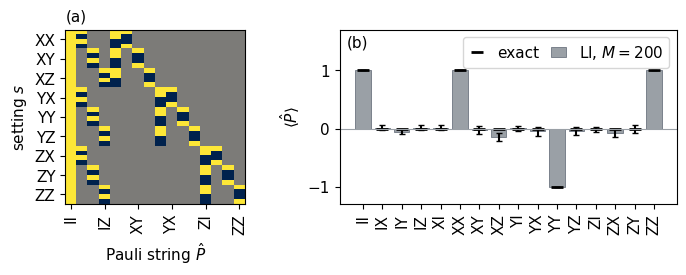

In [6]:
def design_matrix(proj, paulis):
    n_dim = paulis.shape[-1]
    return np.real(np.einsum("sbij,pji->sbp", proj, paulis)).reshape(-1, len(paulis)) / n_dim   # equation (9)

A = design_matrix(PROJ, PAULIS)                                   # (36, 16)
AtA = A.T @ A
assert np.allclose(AtA, np.diag(3.0 ** (N - WEIGHT) / d))         # diagonal, entries 3^(N-k) / 2^N
assert np.linalg.matrix_rank(A) == 4 ** N                         # informationally complete
LI_MAP = np.linalg.pinv(A)                                        # (A^T A)^(-1) A^T of equation (10)
assert np.allclose(LI_MAP, A.T / np.diag(AtA)[:, None])

def linear_inversion(counts):
    # counts (..., 9, 4) -> estimates (..., 4, 4); equation (10) applied to the frequencies
    f = counts / counts.sum(axis=-1, keepdims=True)
    return rho_from_pauli(f.reshape(*f.shape[:-2], -1) @ LI_MAP.T)

for name, rho in STATES.items():                                   # infinite shots: exact frequencies
    assert np.allclose(A @ pauli_vector(rho), born_table(rho).reshape(-1))
    assert np.max(np.abs(linear_inversion(born_table(rho)) - rho)) < 1e-12

# equation (11) written out for one string, compared with the least-squares solution
f_demo = counts_demo / M_DEMO
P_lab = "XZ"; P_idx = LABELS.index(P_lab)
parity = lambda b, lab: (-1) ** sum(bq for bq, c in zip(bits_of(b, N), lab) if c != "I")
compatible = [s for s, name in enumerate(SETTINGS) if all(c == "I" or c == sc for c, sc in zip(P_lab, name))]
r_by_hand = np.mean([sum(parity(b, P_lab) * f_demo[s, b] for b in range(d)) for s in compatible])
r_lstsq = np.linalg.lstsq(A, f_demo.reshape(-1), rcond=None)[0]
assert abs(r_by_hand - r_lstsq[P_idx]) < TOL and np.allclose(r_lstsq, f_demo.reshape(-1) @ LI_MAP.T)

# control: data taken with u_Y = H (S^dagger forgotten) and analysed with the correct design matrix
U_bad = np.array([kron_all([{"X": HAD, "Y": HAD, "Z": I2}[c] for c in s]) for s in SETTINGS])
p_bad = np.real(np.einsum("sbi,ij,sbj->sb", U_bad, rho_rand, U_bad.conj()))
err_bad = np.max(np.abs(linear_inversion(p_bad) - rho_rand))
assert err_bad > 0.05
print(f"infinite shots: linear inversion returns all three states to {max(np.max(np.abs(linear_inversion(born_table(r)) - r)) for r in STATES.values()):.1e}")
print(f"<{P_lab}> from equation (11): {r_by_hand:.4f} = least squares {r_lstsq[P_idx]:.4f}")
print(f"control without S^dagger: largest error of the reconstructed entries {err_bad:.2f} -> detected")

r_li_demo = r_lstsq
sigma_r = np.sqrt(np.clip(1 - r_bell ** 2, 0, None) / (3.0 ** (N - WEIGHT) * M_DEMO))   # equation (11)
def design_panel(ax):
    ax.imshow(A * d, cmap="cividis", aspect="auto", interpolation="nearest")
    ax.set_xticks(range(0, 16, 3)); ax.set_xticklabels(LABELS[::3], rotation=90)
    ax.set_yticks(np.arange(9) * d + 1.5); ax.set_yticklabels(SETTINGS)
    ax.set_xlabel(r"Pauli string $\hat P$"); ax.set_ylabel(r"setting $s$")
def pauli_panel(ax):
    ax.bar(range(16), r_li_demo, color=COL["li"], edgecolor=COL["grey"], lw=0.5, yerr=sigma_r, capsize=2, label="LI, $M=200$")
    ax.plot(range(16), r_bell, "_", ms=9, mew=2, color=COL["exact"], label="exact")
    ax.axhline(0, color=COL["rand"], lw=0.8)
    ax.set_xticks(range(16)); ax.set_xticklabels(LABELS, rotation=90)
    ax.set_ylabel(r"$\langle\hat P\rangle$"); ax.set_ylim(-1.3, 1.7); ax.legend(loc="upper right", ncol=2, handlelength=1.0, columnspacing=0.8)
panels("fig_lab074_design_matrix", [design_panel, pauli_panel], label_xy=[(0.0, 1.03, "bottom"), (0.02, 0.97, "top")], width_ratios=[0.8, 1.5])

Panel (a) shows the design matrix multiplied by $2^N$, with entries $+1$ (yellow), $-1$ (dark) and $0$ (grey). The identity column is filled, each weight-one column has entries in three settings and each weight-two column in one setting. Panel (b) shows the Pauli coefficients estimated from the Bell data of Section 5, with the error bars of equation (11). The four nonzero values are recovered without any error, because every shot of the settings $XX$, $YY$ and $ZZ$ gives the same parity and $\mathrm{Var}(\tilde r_P)=0$ for $r_P=\pm1$. The vanishing coefficients fluctuate around zero, and the weight-one strings fluctuate less than the weight-two strings, since they are averaged over three settings.

#### Weighted least squares

Equation (10) treats all frequencies as equally precise. The variance of a frequency is $p(1-p)/M$, so frequencies close to 0 or 1 are more precise, and weighted least squares minimises $\sum_{b,s}(A\boldsymbol r-\boldsymbol f)_{(s,\mathbf b)}^2/v_s(\mathbf b)$ with estimated variances $v_s(\mathbf b)$. We estimate them with the smoothed frequency $\bar f=(n+1)/(M+2)$, $v=\bar f(1-\bar f)/M$, which avoids a zero variance for outcomes that were never observed, and keep the identity coefficient fixed at one. The code compares the two estimators on 300 data sets of the Werner state with $M=200$.

In [7]:
def weighted_least_squares(counts, shots):
    # counts (9, 4); shots is one number or an array with the number of shots of each of the nine settings
    shots = np.reshape(shots, (-1, 1))
    nbar = (counts + 1) / (shots + 2)
    w = 1.0 / (nbar * (1 - nbar) / shots).reshape(-1)
    rhs = (counts / shots).reshape(-1) - A[:, 0]                # identity coefficient fixed to one
    Aw = A[:, 1:] * w[:, None]
    r = np.linalg.solve(A[:, 1:].T @ Aw, Aw.T @ rhs)
    return rho_from_pauli(np.concatenate([[1.0], r]))

R_WLS = 300
key, k = jax.random.split(key)
counts_w = np.asarray(jax.vmap(sample_counts, in_axes=(0, None, None))(jax.random.split(k, R_WLS), jnp.asarray(born_table(rho_werner)), 200))
hs_ls = hs_distance(rho_werner, linear_inversion(counts_w))
hs_wls = hs_distance(rho_werner, np.array([weighted_least_squares(c, 200) for c in counts_w]))
print(f"Werner state, M = 200, {R_WLS} data sets: mean Hilbert-Schmidt distance, least squares {hs_ls.mean():.4f}, weighted {hs_wls.mean():.4f}")
NUMBERS.update(HSLS=f"{hs_ls.mean():.3f}", HSWLS=f"{hs_wls.mean():.3f}")

Werner state, M = 200, 300 data sets: mean Hilbert-Schmidt distance, least squares 0.1036, weighted 0.1020


For this complete and balanced set of settings the weighting changes the error only slightly. Weighted least squares helps more when the settings are not equivalent, for example when some settings are measured with more shots than others or when the measurement has unequal efficiencies. Like linear inversion, it does not enforce a non-negative density matrix.

## 7. Unphysical estimates

The one-qubit example of Section 3 already produced Bloch vectors outside the unit ball. For two qubits the same happens when $\tilde\rho_{\mathrm{LI}}$ has a negative eigenvalue. The statistical noise of equation (11) is spread over all 15 coefficients, and the eigenvalues of $\tilde\rho_{\mathrm{LI}}$ fluctuate by roughly $D_{\mathrm{HS}}$. When the true state has eigenvalues close to zero, as every pure state has, the noise pushes some of them below zero. To see how often this happens, we draw 400 independent data sets for each of the three states and each of the budgets $M=20$, $200$ and $2000$ shots per setting, with the sampler of Section 5 under `jax.vmap` over the data sets, and record the smallest eigenvalue $\lambda_{\min}$ of every linear-inversion estimate. These data sets are used again in Sections 8 to 10.

Bell   : fraction of estimates with a negative eigenvalue at M = 20, 200, 2000: 1.00, 1.00, 1.00
Werner : fraction of estimates with a negative eigenvalue at M = 20, 200, 2000: 1.00, 0.51, 0.00
random : fraction of estimates with a negative eigenvalue at M = 20, 200, 2000: 0.93, 0.11, 0.00


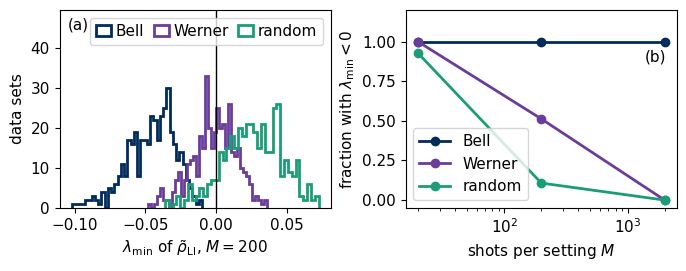

In [8]:
M_LIST = (20, 200, 2000)
R_REP = 400
sample_many = jax.jit(jax.vmap(sample_counts, in_axes=(0, None, None)), static_argnums=2)
DATA = {}
for name, rho in STATES.items():
    for M in M_LIST:
        key, k = jax.random.split(key)
        DATA[name, M] = np.asarray(sample_many(jax.random.split(k, R_REP), jnp.asarray(born_table(rho)), M))
RHO_LI = {nm: linear_inversion(c) for nm, c in DATA.items()}
LAM_MIN = {nm: np.linalg.eigvalsh(r)[:, 0] for nm, r in RHO_LI.items()}
neg_frac = {nm: float(np.mean(l < 0)) for nm, l in LAM_MIN.items()}
for name in STATES:
    print(f"{name:7s}: fraction of estimates with a negative eigenvalue at M = 20, 200, 2000:",
          ", ".join(f"{neg_frac[name, M]:.2f}" for M in M_LIST))
    for M in M_LIST:
        NUMBERS[f"NegFrac{name.capitalize()}{WORD[M]}"] = f"{100 * neg_frac[name, M]:.0f}"
assert neg_frac["Bell", 200] == 1.0

cols = {"Bell": COL["navy"], "Werner": COL["purple"], "random": COL["teal"]}
def lam_hist(ax):
    for name in STATES:
        ax.hist(LAM_MIN[name, 200], bins=40, histtype="step", lw=2, color=cols[name], label=name)
    ax.axvline(0, color=COL["exact"], lw=1)
    ax.set_ylim(0, 1.5 * max(np.histogram(LAM_MIN[nm, 200], bins=40)[0].max() for nm in STATES))
    ax.set_xlabel(r"$\lambda_{\min}$ of $\tilde\rho_{\mathrm{LI}}$, $M=200$"); ax.set_ylabel("data sets")
    ax.legend(loc="upper right", ncol=3, handlelength=1.0, columnspacing=0.6, handletextpad=0.3)
def neg_frac_panel(ax):
    for name in STATES:
        ax.semilogx(M_LIST, [neg_frac[name, M] for M in M_LIST], "o-", color=cols[name], lw=2, label=name)
    ax.set_xlabel(r"shots per setting $M$"); ax.set_ylabel(r"fraction with $\lambda_{\min}<0$"); ax.set_ylim(-0.05, 1.2)
    ax.legend(loc="lower left")
panels("fig_lab074_negative_eigenvalues", [lam_hist, neg_frac_panel], label_xy=[(0.03, 0.96, "top"), (0.88, 0.80, "top")])

Panel (a) shows the distribution of $\lambda_{\min}$ at $M=200$. For the Bell state, whose true eigenvalues are $1,0,0,0$, every estimate has a negative eigenvalue. For the Werner state, whose three small eigenvalues equal $(1-v)/4=0.05$, and for the random state the distribution lies below the true smallest eigenvalue, because the smallest of several noisy eigenvalues is shifted downwards, and it crosses zero in part of the data sets. Panel (b) shows how this fraction depends on $M$. For a pure state it stays at one for every budget, because the true eigenvalue zero is surrounded by noise of both signs. For a full-rank state it decreases once the noise becomes smaller than the smallest true eigenvalue. A linear-inversion estimate of a nearly pure state is therefore unphysical in practice, and a negative eigenvalue gives negative probabilities for some measurements.

## 8. Projection onto the physical states

A first repair replaces $\tilde\rho_{\mathrm{LI}}$ by the closest physical state in the Hilbert–Schmidt distance,
$$\tilde\rho_{\mathrm{proj}}=\arg\min_{\hat\sigma\ge0,\ \mathrm{Tr}\hat\sigma=1}\big\|\tilde\rho_{\mathrm{LI}}-\hat\sigma\big\|_{\mathrm{HS}} . \tag{12}$$
The minimiser has the eigenvectors of $\tilde\rho_{\mathrm{LI}}$, and only the eigenvalues change [11]. With the eigenvalues $\lambda_1\ge\dots\ge\lambda_d$ of $\tilde\rho_{\mathrm{LI}}$, the new eigenvalues are
$$\mu_i=\max(\lambda_i-\tau,\,0) , \tag{13}$$
where the shift $\tau$ is fixed by $\sum_i\mu_i=1$. The algorithm of Ref. [11] finds $\tau$ by walking up from the smallest eigenvalue. While the smallest remaining eigenvalue is negative, it is set to zero and its negative weight is distributed equally over the remaining ones, which lowers all of them. A small positive eigenvalue can become negative through this lowering, and it is then set to zero as well. The function `project_eigenvalues` in the code reaches the same result for many estimates at once. When the $k$ largest eigenvalues are kept, the unit trace fixes the shift $\tau_k=(\lambda_1+\dots+\lambda_k-1)/k$, and the walk ends at the largest $k$ for which the smallest kept eigenvalue stays positive, $\lambda_k-\tau_k>0$.

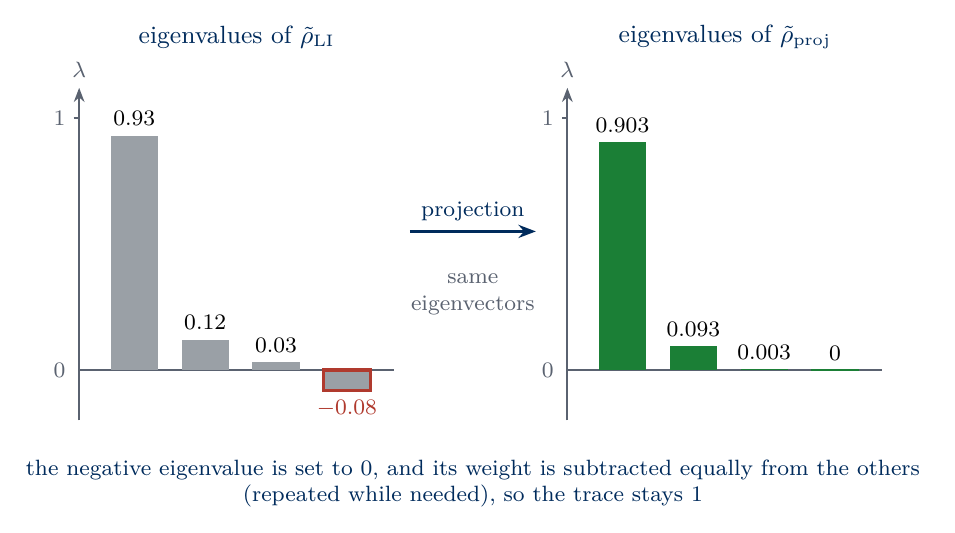

*Eigenvalues of a linear-inversion estimate with a negative eigenvalue (left) and of its projection (right). Negative eigenvalues are set to zero and the others are lowered by a common shift.*

Equation (12) asks for the point of a convex set closest to a given matrix. A physical state $\tilde\rho$ is this closest point if and only if $\mathrm{Tr}[(\tilde\rho_{\mathrm{LI}}-\tilde\rho)(\hat\sigma-\tilde\rho)]\le0$ for every physical $\hat\sigma$. Geometrically, the step from $\tilde\rho$ to any other physical state $\hat\sigma$ makes an angle of at least ninety degrees with the step from $\tilde\rho$ to $\tilde\rho_{\mathrm{LI}}$, so every move inside the set of physical states increases the distance to $\tilde\rho_{\mathrm{LI}}$. Since the largest value of $\mathrm{Tr}(\hat\Delta\hat\sigma)$ over physical states is the largest eigenvalue of $\hat\Delta$, the condition is equivalent to the projection certificate
$$\lambda_{\max}(\hat\Delta)-\mathrm{Tr}(\hat\Delta\tilde\rho)\le0,\qquad \hat\Delta=\tilde\rho_{\mathrm{LI}}-\tilde\rho . \tag{14}$$
We use it to test our implementation and, as a control, a common shortcut that sets negative eigenvalues to zero and rescales the rest to unit trace. The shortcut also gives a physical state, but it violates equation (14). A projection onto a convex set that contains the true state can only reduce the Hilbert–Schmidt distance to the true state, and we check this property on all 3600 data sets of Section 7.

projection certificate (14): projection 1.5e-15 (largest over 450 data sets), clip-and-rescale at least 4.5e-04 -> detected
Bell, M = 200: projection lowers the trace distance to the true state in 100% of the data sets


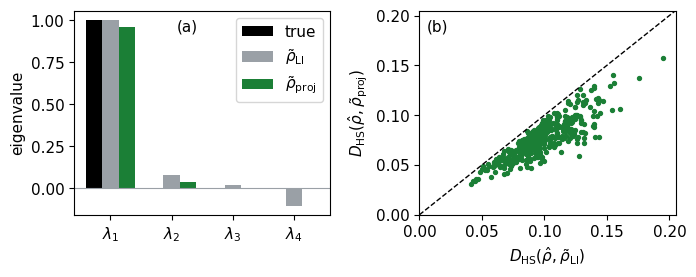

In [9]:
def project_eigenvalues(lam):
    # Equation (13) for a stack of eigenvalue vectors (..., d) with unit sum. This is the walk of Smolin, Gambetta and
    # Smith without a loop. If the k largest eigenvalues are kept and the others are set to zero, the unit trace fixes
    #     tau_k = (lambda_1 + ... + lambda_k - 1) / k .
    # The walk drops the smallest remaining eigenvalue while lambda_k - tau_k < 0, so it ends at the largest k with
    # lambda_k - tau_k > 0. The function sgs_eigenvalues below is the same walk written as a loop.
    mu = -np.sort(-lam, axis=-1)                         # eigenvalues in decreasing order, lambda_1 >= ... >= lambda_d
    css = np.cumsum(mu, axis=-1)                         # css[k-1] = lambda_1 + ... + lambda_k
    k = np.arange(1, lam.shape[-1] + 1)                  # k = 1, ..., d
    keep = mu - (css - 1) / k > 0                        # lambda_k - tau_k > 0: True for the kept k, False above them
    last = lam.shape[-1] - 1 - np.argmax(keep[..., ::-1], axis=-1)   # position of the last True (first True of the reversed row)
    tau = (np.take_along_axis(css, last[..., None], axis=-1)[..., 0] - 1) / (last + 1)   # tau_k of that k = last + 1
    return np.clip(lam - tau[..., None], 0, None)        # mu_i = max(lambda_i - tau, 0)

def project_physical(rho):
    w, v = np.linalg.eigh(rho)
    return (v * project_eigenvalues(w)[..., None, :]) @ v.conj().swapaxes(-1, -2)

def sgs_eigenvalues(lam):
    # the algorithm of Smolin, Gambetta and Smith for one eigenvalue vector with unit sum
    mu = sorted(lam, reverse=True); i, a = len(mu), 0.0     # i eigenvalues remain, a is the weight removed so far (negative)
    while mu[i - 1] + a / i < 0:                            # the smallest remaining one is negative after sharing a
        a += mu[i - 1]; mu[i - 1] = 0.0; i -= 1             # set it to zero and add its weight to a
    return np.array([m + a / i if j < i else 0.0 for j, m in enumerate(mu)])   # the i kept ones share a equally

def clip_and_rescale(rho):                                       # the control, physical but not the closest state
    w, v = np.linalg.eigh(rho); w = np.clip(w, 0, None); w /= w.sum()
    return (v * w[..., None, :]) @ v.conj().swapaxes(-1, -2)

def certificate(rho_li, rho_phys):                               # left-hand side of equation (14)
    G = rho_li - rho_phys
    return np.linalg.eigvalsh(G)[-1] - np.real(np.trace(G @ rho_phys))

lam_demo = np.linalg.eigvalsh(RHO_LI["Bell", 200][:50])
for lam in lam_demo:
    assert np.allclose(np.sort(project_eigenvalues(lam))[::-1], sgs_eigenvalues(lam))
RHO_PROJ = {nm: project_physical(r) for nm, r in RHO_LI.items()}
worst_cert = max(certificate(rli, rp) for nm in DATA for rli, rp in zip(RHO_LI[nm][:50], RHO_PROJ[nm][:50]))
cert_clip = np.array([certificate(rli, clip_and_rescale(rli)) for rli in RHO_LI["Bell", 200][:50]])
assert worst_cert < 1e-12 and cert_clip.min() > 1e-6
for nm in DATA:
    assert np.min(np.linalg.eigvalsh(RHO_PROJ[nm])) > -1e-12
    assert np.all(hs_distance(STATES[nm[0]], RHO_PROJ[nm]) <= hs_distance(STATES[nm[0]], RHO_LI[nm]) + 1e-12)
better_D = np.mean(trace_distance(rho_bell, RHO_PROJ["Bell", 200]) < trace_distance(rho_bell, RHO_LI["Bell", 200]))
print(f"projection certificate (14): projection {worst_cert:.1e} (largest over 450 data sets), clip-and-rescale at least {cert_clip.min():.1e} -> detected")
print(f"Bell, M = 200: projection lowers the trace distance to the true state in {better_D:.0%} of the data sets")
NUMBERS.update(ProjBetterBell=f"{100 * better_D:.0f}")

i0 = int(np.argmin(LAM_MIN["Bell", 200]))                       # the data set with the most negative eigenvalue
lam_li = np.sort(np.linalg.eigvalsh(RHO_LI["Bell", 200][i0]))[::-1]
lam_pr = np.sort(np.linalg.eigvalsh(RHO_PROJ["Bell", 200][i0]))[::-1]
hl, hp = hs_distance(rho_bell, RHO_LI["Bell", 200]), hs_distance(rho_bell, RHO_PROJ["Bell", 200])
def spectrum_panel(ax):
    w_ = 0.27
    ax.bar(np.arange(4) - w_, [1, 0, 0, 0], w_, color=COL["exact"], label="true")
    ax.bar(np.arange(4), lam_li, w_, color=COL["li"], label=r"$\tilde\rho_{\mathrm{LI}}$")
    ax.bar(np.arange(4) + w_, lam_pr, w_, color=COL["proj"], label=r"$\tilde\rho_{\mathrm{proj}}$")
    ax.axhline(0, color=COL["rand"], lw=0.8)
    ax.set_xticks(range(4)); ax.set_xticklabels([r"$\lambda_1$", r"$\lambda_2$", r"$\lambda_3$", r"$\lambda_4$"])
    ax.set_ylabel("eigenvalue"); ax.legend(loc="upper right")
def hs_panel(ax):
    ax.scatter(hl, hp, s=8, color=COL["proj"])
    lim = [0, 1.05 * hl.max()]
    ax.plot(lim, lim, color=COL["exact"], ls="--", lw=1)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(r"$D_{\mathrm{HS}}(\hat\rho,\tilde\rho_{\mathrm{LI}})$"); ax.set_ylabel(r"$D_{\mathrm{HS}}(\hat\rho,\tilde\rho_{\mathrm{proj}})$")
panels("fig_lab074_projection", [spectrum_panel, hs_panel], label_xy=[(0.40, 0.96, "top"), (0.03, 0.96, "top")])

Panel (a) shows the spectrum of the Bell-state estimate with the most negative eigenvalue at $M=200$. The projection sets the negative eigenvalue $\lambda_4$ and the small positive eigenvalue $\lambda_3$ to zero and lowers $\lambda_1$ and $\lambda_2$ by the same shift, and the result is closer to the true spectrum $1,0,0,0$. Panel (b) compares the Hilbert–Schmidt distance to the true state before and after the projection for all 400 data sets, and every point lies below the diagonal. The projection repairs the estimate at almost no cost, an eigendecomposition of a $2^N\times2^N$ matrix. It uses the data only through $\tilde\rho_{\mathrm{LI}}$, which treats all frequencies as equally precise.

## 9. Maximum likelihood

Maximum-likelihood estimation searches directly among physical states for the one under which the observed counts are most probable [12]. With the counts $n_s(\mathbf b)$, the logarithm of the probability of the data is, up to a constant,
$$\ell(\hat\rho)=\sum_{s}\sum_{\mathbf b}n_s(\mathbf b)\ln\mathrm{Tr}\big[\hat\rho\,\hat\pi_{s,\mathbf b}\big] , \tag{15}$$
measured in nats, and the estimate is $\tilde\rho_{\mathrm{MLE}}=\arg\max\ell(\hat\rho)$ over physical states. To find the condition for the maximum, we move from $\hat\rho$ a small step towards another physical state $\hat\sigma$, along $\hat\rho_\epsilon=(1-\epsilon)\hat\rho+\epsilon\hat\sigma$, which is physical for $0\le\epsilon\le1$. Every probability is linear in the state, $p_s(\mathbf b|\hat\rho_\epsilon)=(1-\epsilon)\,p_s(\mathbf b|\hat\rho)+\epsilon\,p_s(\mathbf b|\hat\sigma)$ with $p_s(\mathbf b|\hat\rho)=\mathrm{Tr}[\hat\rho\,\hat\pi_{s,\mathbf b}]$, so the derivative of equation (15) at $\epsilon=0$ is
$$\frac{d\ell(\hat\rho_\epsilon)}{d\epsilon}\bigg|_{\epsilon=0}=\sum_{s,\mathbf b}n_s(\mathbf b)\,\frac{p_s(\mathbf b|\hat\sigma)-p_s(\mathbf b|\hat\rho)}{p_s(\mathbf b|\hat\rho)}=\sum_{s,\mathbf b}\frac{n_s(\mathbf b)}{p_s(\mathbf b|\hat\rho)}\mathrm{Tr}\big[\hat\sigma\,\hat\pi_{s,\mathbf b}\big]-3^NM=3^NM\,\big[\mathrm{Tr}(\hat R\hat\sigma)-1\big] ,$$
where the counts sum to the total number of shots $3^NM$, the frequencies are $f_s(\mathbf b)=n_s(\mathbf b)/M$ and the last step collects the sum into the operator
$$\hat R(\hat\rho)=\frac{1}{3^N}\sum_{s,\mathbf b}\frac{f_s(\mathbf b)}{p_s(\mathbf b|\hat\rho)}\,\hat\pi_{s,\mathbf b} . \tag{16}$$
The operator $\hat R$ is Hermitian with non-negative eigenvalues, and $\mathrm{Tr}(\hat R\hat\rho)=3^{-N}\sum_{s,\mathbf b}f_s(\mathbf b)=1$ for every $\hat\rho$. If the model reproduced the frequencies, every ratio $f/p$ would equal one and $\hat R=\hat I$, because the projectors of the nine settings sum to $3^N\hat I$.

At the maximum $\tilde\rho$ no direction increases $\ell$, so $\mathrm{Tr}(\hat R\hat\sigma)\le1$ for every physical $\hat\sigma$. The largest value of $\mathrm{Tr}(\hat R\hat\sigma)$ over physical states is the largest eigenvalue of $\hat R$, so no eigenvalue of $\hat R$ exceeds one. In the eigenbasis $|i\rangle$ of $\hat R$ with eigenvalues $r_i$, the trace $\mathrm{Tr}(\hat R\tilde\rho)=\sum_ir_i\langle i|\tilde\rho|i\rangle$ is an average of the $r_i\le1$ with weights that sum to one. This average equals one, so $\tilde\rho$ has weight only on eigenvectors with $r_i=1$, and therefore
$$\hat R(\tilde\rho)\,\tilde\rho=\tilde\rho,\qquad \lambda_{\max}\big[\hat R(\tilde\rho)\big]=1 .$$
Taking the Hermitian conjugate gives $\tilde\rho\hat R=\tilde\rho$ as well, hence $\hat R\tilde\rho\hat R=\tilde\rho$. The maximum of the likelihood is therefore a fixed point of the iteration
$$\hat\rho_{t+1}=\frac{\hat R(\hat\rho_t)\,\hat\rho_t\,\hat R(\hat\rho_t)}{\mathrm{Tr}\big[\hat R(\hat\rho_t)\,\hat\rho_t\,\hat R(\hat\rho_t)\big]} , \tag{17}$$
the $R\rho R$ algorithm [12], started at $\hat I/d$, where $t$ counts the iterations. Multiplying by $\hat R$ from both sides keeps every iterate Hermitian and positive semidefinite, and the denominator keeps the unit trace. The iteration is not guaranteed to increase $\ell$ in every step, and the diluted variant $\hat\rho\to(\hat I+\epsilon\hat R)\hat\rho(\hat I+\epsilon\hat R)$ with small $\epsilon$ restores this guarantee [13]. We record $\ell$ along the iteration and check that it never decreases for our data.

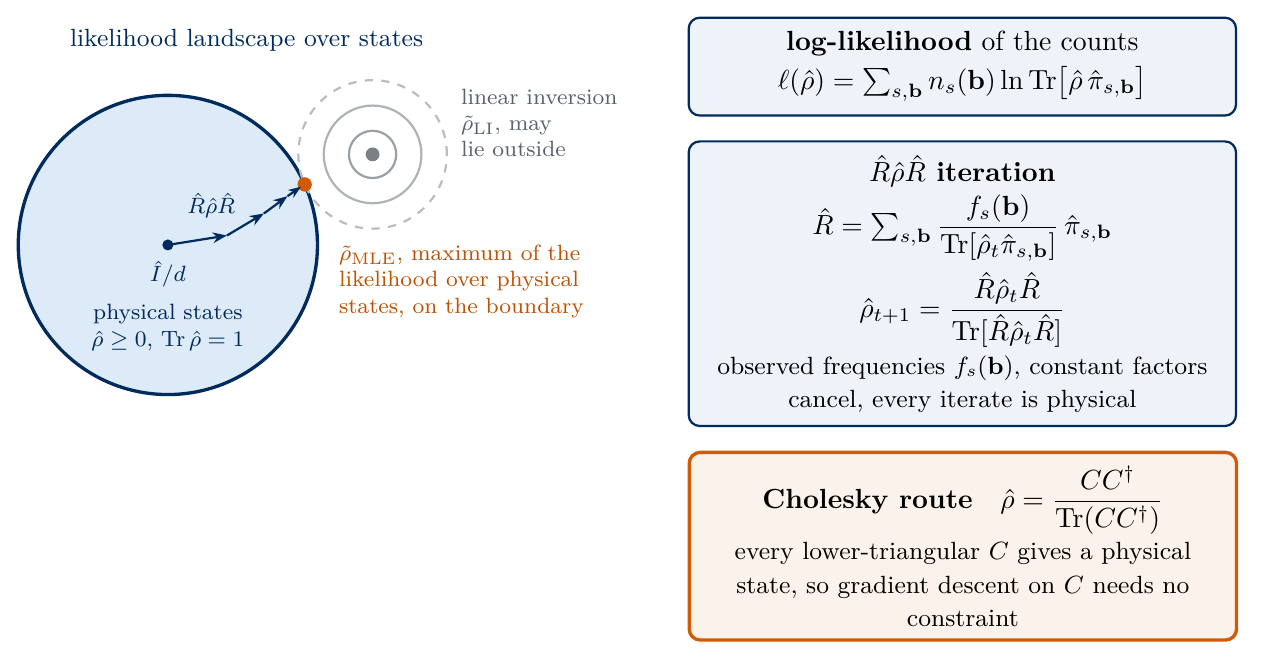

*Maximum likelihood over the physical states. The grey contours sketch the likelihood around its unconstrained maximum. The linear-inversion estimate that labels this point lies close to it and coincides with it only when one matrix reproduces all 36 frequencies. The $R\rho R$ iteration starts at $\hat I/d$ and moves towards the most likely physical state, which lies on the boundary when the unconstrained maximum is unphysical, the case drawn here. The Cholesky form gives a physical state for every $C$, so gradient descent on $C$ needs no constraint. The sketch writes $\hat R$ without the factor $3^{-N}$ of equation (16), which cancels in the normalised iteration.*

The second algorithm uses the Cholesky decomposition. Every positive semidefinite matrix can be written as $CC^\dagger$ with a lower-triangular complex matrix $C$ with real diagonal, its Cholesky factor, and $CC^\dagger$ is positive semidefinite for every such $C$. The state
$$\hat\rho(C)=\frac{CC^\dagger}{\mathrm{Tr}(CC^\dagger)} \tag{18}$$
is therefore physical for every $C$, and every physical state has this form [2,14]. For two qubits $C$ has $4$ real diagonal entries and 6 complex entries below the diagonal, 16 real parameters. A two-qubit state has 15 parameters, and the additional one is the overall scale of $C$, which the normalisation in equation (18) removes. We minimise $-\ell/(3^NM)$, the negative log-likelihood per shot, with gradients from `jax.grad` [15] and the Adam optimiser [16] with a slowly decreasing step size. Both loops are written with `jax.lax.scan` (Section 1). Both algorithms are applied to one data set of the Werner state with $M=2000$, whose maximum lies inside the set of physical states, and must agree. We then check the likelihood certificate $\lambda_{\max}(\hat R)=1$ and apply the same test to the projected estimate, which is physical and lies below the maximum of the likelihood. The cell takes about five seconds.

R rho R and Cholesky + Adam: largest difference of the entries 1.1e-16, of the log-likelihood per shot 0.0e+00
largest eigenvalue of R: 1.000000000000 at the maximum, 1.0265 at the projected estimate -> not the maximum
eigenvalues: MLE [0.0383 0.0485 0.0612 0.8521]  projection [0.0347 0.0459 0.0667 0.8526]


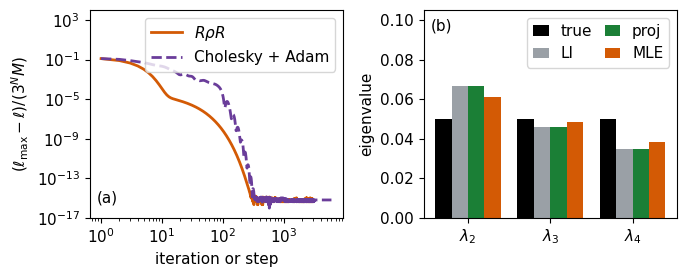

In [10]:
PROJ_J = jnp.asarray(PROJ)
MLE_ITERS = 400

def probs_of(rho):
    return jnp.real(jnp.einsum("sbij,ji->sb", PROJ_J, rho))

def R_operator(rho, f):
    return jnp.einsum("sb,sbij->ij", f / jnp.clip(probs_of(rho), 1e-300), PROJ_J) / 3 ** N   # equation (16)

def loglik_per_shot(rho, f):
    return jnp.sum(f * jnp.log(jnp.clip(probs_of(rho), 1e-300))) / 3 ** N                  # equation (15) / (3^N M)

@partial(jax.jit, static_argnums=1)
def rrr(f, iters=MLE_ITERS):
    # equation (17) from the maximally mixed state; returns the estimate and the log-likelihood per shot of every iterate
    def step(rho, _):                                 # one iteration: the carry is rho, the recorded value is the log-likelihood
        R = R_operator(rho, f)
        new = R @ rho @ R
        return new / jnp.trace(new), loglik_per_shot(rho, f)
    return jax.lax.scan(step, jnp.eye(d, dtype=complex) / d, None, length=iters)   # compiled loop of `iters` steps

TRIL = np.tril_indices(d, -1)
def rho_of_params(x):
    # x holds the 16 real parameters of the Cholesky factor C: 4 diagonal entries, then real and imaginary parts below the diagonal
    C = jnp.diag(x[:d]).astype(complex).at[TRIL].set(x[d:d + 6] + 1j * x[d + 6:])       # .at[].set returns a new array
    CC = C @ C.conj().T
    return CC / jnp.trace(CC)                                                               # equation (18)

@partial(jax.jit, static_argnums=2)
def cholesky_mle(f, x0, steps=6000, lr=0.05, decay=0.998, b1=0.9, b2=0.999, eps=1e-12):
    value_and_grad = jax.value_and_grad(lambda x: -loglik_per_shot(rho_of_params(x), f))
    def step(carry, t):                            # one Adam step: the carry is (parameters, m, v), the recorded value is the loss
        x, m, v = carry
        L, g = value_and_grad(x)
        m = b1 * m + (1 - b1) * g                  # running average of the gradient
        v = b2 * v + (1 - b2) * g ** 2             # running average of its square
        m_hat, v_hat = m / (1 - b1 ** (t + 1)), v / (1 - b2 ** (t + 1))
        return (x - lr * decay ** t * m_hat / (jnp.sqrt(v_hat) + eps), m, v), L
    zeros = jnp.zeros_like(x0)
    (x, _, _), history = jax.lax.scan(step, (x0, zeros, zeros), jnp.arange(steps))   # compiled loop over t = 0, ..., steps - 1
    return x, history

counts_mle = DATA["Werner", 2000][0]
f_mle = jnp.asarray(counts_mle / 2000)
rho_rrr, ll_rrr = rrr(f_mle, 3000)
x0 = jnp.concatenate([0.5 * jnp.ones(d), jnp.zeros(12)])
x_opt, nll_adam = cholesky_mle(f_mle, x0)
rho_chol = np.asarray(rho_of_params(x_opt))
rho_rrr, ll_rrr, nll_adam = np.asarray(rho_rrr), np.asarray(ll_rrr), np.asarray(nll_adam)
diff_rho = np.max(np.abs(rho_rrr - rho_chol))
diff_ll = abs(-nll_adam[-1] - float(loglik_per_shot(rho_rrr, f_mle)))
assert np.all(np.diff(ll_rrr) > -1e-13)                          # the log-likelihood never decreases
assert diff_rho < 1e-9 and diff_ll < 1e-12
lam_R = np.linalg.eigvalsh(np.asarray(R_operator(rho_rrr, f_mle)))
rho_proj_mle = project_physical(linear_inversion(counts_mle))
lam_R_proj = np.linalg.eigvalsh(np.asarray(R_operator(jnp.asarray(rho_proj_mle), f_mle)))
assert abs(lam_R[-1] - 1) < 1e-9 and lam_R_proj[-1] > 1 + 1e-4
assert float(loglik_per_shot(rho_rrr, f_mle)) >= float(loglik_per_shot(jnp.asarray(rho_proj_mle), f_mle))
print(f"R rho R and Cholesky + Adam: largest difference of the entries {diff_rho:.1e}, of the log-likelihood per shot {diff_ll:.1e}")
print(f"largest eigenvalue of R: {lam_R[-1]:.12f} at the maximum, {lam_R_proj[-1]:.4f} at the projected estimate -> not the maximum")
print("eigenvalues: MLE", np.round(np.linalg.eigvalsh(rho_rrr), 4), " projection", np.round(np.linalg.eigvalsh(rho_proj_mle), 4))
NUMBERS.update(MLEDiffRho=sci(max(diff_rho, 1e-16), 0), RMaxProj=f"{lam_R_proj[-1]:.3f}")

ll_max = max(ll_rrr.max(), -nll_adam.min())
ev = {"true": np.linalg.eigvalsh(rho_werner)[::-1], "LI": np.linalg.eigvalsh(linear_inversion(counts_mle))[::-1],
      "proj": np.linalg.eigvalsh(rho_proj_mle)[::-1], "MLE": np.linalg.eigvalsh(rho_rrr)[::-1]}
def convergence_panel(ax):
    ax.semilogy(np.arange(1, 3001), np.maximum(ll_max - ll_rrr, 1e-16), color=COL["mle"], lw=2, label=r"$R\rho R$")
    ax.semilogy(np.arange(1, 6001), np.maximum(ll_max + nll_adam, 1e-16), color=COL["purple"], lw=2, ls="--", label="Cholesky + Adam")
    ax.set_xlabel("iteration or step"); ax.set_ylabel(r"$(\ell_{\max}-\ell)/(3^NM)$"); ax.set_ylim(1e-17, 1e4); ax.legend(loc="upper right")
    ax.set_xscale("log")
def eigen_panel(ax):
    w_ = 0.2
    for j, (lab, c) in enumerate(zip(ev, (COL["exact"], COL["li"], COL["proj"], COL["mle"]))):
        ax.bar(np.arange(1, 4) + (j - 1.5) * w_, ev[lab][1:], w_, color=c, label=lab)
    ax.set_xticks(range(1, 4)); ax.set_xticklabels([r"$\lambda_2$", r"$\lambda_3$", r"$\lambda_4$"])
    ax.set_ylabel("eigenvalue"); ax.set_ylim(0, 0.105); ax.legend(loc="upper right", ncol=2, handlelength=1.0, columnspacing=0.8)
panels("fig_lab074_mle", [convergence_panel, eigen_panel], label_xy=[(0.03, 0.06, "bottom"), (0.03, 0.96, "top")])

Panel (a) shows the distance of the log-likelihood per shot from its maximum along both algorithms. The $R\rho R$ iteration reaches the maximum to machine precision smoothly after about 300 iterations, and Adam after about 500 steps with oscillations that the decreasing step size damps. The two estimates agree to numerical precision. Panel (b) compares the three small eigenvalues of the Werner state, all equal to $0.05$, with those of the three estimates from the same data. The linear-inversion estimate of this data set is already physical, so the projection leaves it unchanged. The maximum-likelihood estimate differs from it, and the likelihood certificate, violated with $\lambda_{\max}(\hat R)>1$, shows that the projected estimate does not maximise the likelihood. In the next section we use $R\rho R$ with 400 iterations, since it needs no step size and runs on many data sets at once, and we check that more iterations do not change the result.

## 10. Error versus the number of shots

Each frequency has a statistical error proportional to $M^{-1/2}$, and so do the linear-inversion coefficients of equation (11). Every distance that is linear in the error of the estimate, such as the trace distance and the Hilbert–Schmidt distance, therefore decreases as
$$D\propto M^{-1/2} . \tag{19}$$
For a pure true state $|\psi\rangle$ the infidelity $1-F$ of a physical estimate equals $1-\langle\psi|\tilde\rho|\psi\rangle$, the weight of the estimate outside $|\psi\rangle$. A rotation of the dominant eigenvector of the estimate by a small angle of order $M^{-1/2}$ contributes to this weight the square of the angle, of order $M^{-1}$, whereas additional small eigenvalues of the estimate contribute their sum. The infidelity therefore decreases as $M^{-1}$ when the small eigenvalues are of order $M^{-1}$ as well. We expect this for the maximum-likelihood estimate of the Bell state, which is an eigenstate of three of the nine measured settings, so that the outcomes of zero probability in these settings never occur in the data. A generic pure state has no such setting, and we measure its decrease with Haar-random pure states at the end of this section. The projected estimate keeps a weight of order $M^{-1/2}$ outside $|\psi\rangle$, as in panel (a) of the projection figure of Section 8, where the largest eigenvalue is $0.96$ in place of one, so its infidelity can only fall as $M^{-1/2}$. For full-rank states $1-F$ is approximately a quadratic form in the deviation $\tilde\rho-\hat\rho$ close to the true state, which suggests $M^{-1}$ only asymptotically. For the unphysical $\tilde\rho_{\mathrm{LI}}$ the fidelity is not defined. We apply linear inversion, projection and maximum likelihood to all 3600 data sets of Section 7, the maximum-likelihood step vectorised over data sets with `jax.vmap`, and fit the slopes of the mean errors on a log-log scale. The cell takes about eight seconds.

Bell, M = 2000: largest change of 1-F between 400 and 1600 iterations 3.3e-16 (mean 1-F 1.5e-04)
Bell    slopes: trace distance LI -0.50, proj -0.48, MLE -0.50;  infidelity proj -0.52, MLE -1.00
         MLE estimates on the boundary (lambda_min < 1e-6) at M = 20, 200, 2000: 1.00, 1.00, 1.00
Werner  slopes: trace distance LI -0.50, proj -0.44, MLE -0.43;  infidelity proj -0.81, MLE -0.81
         MLE estimates on the boundary (lambda_min < 1e-6) at M = 20, 200, 2000: 0.99, 0.20, 0.00
random  slopes: trace distance LI -0.50, proj -0.46, MLE -0.47;  infidelity proj -0.94, MLE -0.94
         MLE estimates on the boundary (lambda_min < 1e-6) at M = 20, 200, 2000: 0.85, 0.03, 0.00
Bell, M =   20: mean D  LI 0.2687  proj 0.1734  MLE 0.1134;  mean 1-F  proj 7.80e-02  MLE 1.41e-02
Bell, M =  200: mean D  LI 0.0854  proj 0.0587  MLE 0.0350;  mean 1-F  proj 2.35e-02  MLE 1.34e-03
Bell, M = 2000: mean D  LI 0.0270  proj 0.0192  MLE 0.0113;  mean 1-F  proj 7.24e-03  MLE 1.38e-04


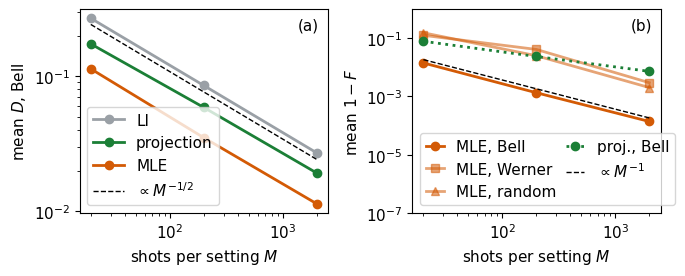

In [11]:
rrr_batch = jax.jit(jax.vmap(lambda f: rrr(f)[0]))
RHO_MLE = {nm: np.asarray(rrr_batch(jnp.asarray(c / nm[1]))) for nm, c in DATA.items()}
rho_long = np.asarray(jax.vmap(lambda f: rrr(f, 4 * MLE_ITERS)[0])(jnp.asarray(DATA["Bell", 2000][:50] / 2000)))
inf_short, inf_long = 1 - fidelity(rho_bell, RHO_MLE["Bell", 2000][:50]), 1 - fidelity(rho_bell, rho_long)
assert np.max(np.abs(inf_short - inf_long)) < 1e-3 * inf_long.mean()       # 400 iterations suffice
print(f"Bell, M = 2000: largest change of 1-F between {MLE_ITERS} and {4 * MLE_ITERS} iterations {np.max(np.abs(inf_short - inf_long)):.1e} (mean 1-F {inf_long.mean():.1e})")
ERR = {}
for (name, M) in DATA:
    rho = STATES[name]
    ERR[name, M] = dict(D_li=trace_distance(rho, RHO_LI[name, M]).mean(), D_proj=trace_distance(rho, RHO_PROJ[name, M]).mean(),
                        D_mle=trace_distance(rho, RHO_MLE[name, M]).mean(), inf_proj=(1 - fidelity(rho, RHO_PROJ[name, M])).mean(),
                        inf_mle=(1 - fidelity(rho, RHO_MLE[name, M])).mean(),
                        boundary_mle=np.mean(np.linalg.eigvalsh(RHO_MLE[name, M])[:, 0] < 1e-6))
def slope(name, q):
    return np.polyfit(np.log10(M_LIST), np.log10([ERR[name, M][q] for M in M_LIST]), 1)[0]
SLOPES = {name: {q: float(slope(name, q)) for q in ("D_li", "D_proj", "D_mle", "inf_proj", "inf_mle")} for name in STATES}
for name in STATES:
    print(f"{name:7s} slopes: trace distance LI {SLOPES[name]['D_li']:+.2f}, proj {SLOPES[name]['D_proj']:+.2f}, MLE {SLOPES[name]['D_mle']:+.2f};"
          f"  infidelity proj {SLOPES[name]['inf_proj']:+.2f}, MLE {SLOPES[name]['inf_mle']:+.2f}")
    print(f"         MLE estimates on the boundary (lambda_min < 1e-6) at M = 20, 200, 2000: "
          + ", ".join(f"{ERR[name, M]['boundary_mle']:.2f}" for M in M_LIST))
for M in M_LIST:
    e = ERR["Bell", M]
    print(f"Bell, M = {M:4d}: mean D  LI {e['D_li']:.4f}  proj {e['D_proj']:.4f}  MLE {e['D_mle']:.4f};  mean 1-F  proj {e['inf_proj']:.2e}  MLE {e['inf_mle']:.2e}")
for name in STATES:
    assert all(-0.62 < SLOPES[name][q] < -0.38 for q in ("D_li", "D_proj", "D_mle"))
assert -1.2 < SLOPES["Bell"]["inf_mle"] < -0.8
NUMBERS.update(SlopeDLIBell=f"{SLOPES['Bell']['D_li']:.2f}", SlopeDMLEBell=f"{SLOPES['Bell']['D_mle']:.2f}",
               SlopeInfMLEBell=f"{SLOPES['Bell']['inf_mle']:.2f}", SlopeInfMLEWerner=f"{SLOPES['Werner']['inf_mle']:.2f}",
               SlopeInfMLERandom=f"{SLOPES['random']['inf_mle']:.2f}",
               InfMLEBellTwoThousand=sci(ERR["Bell", 2000]["inf_mle"], 0), RepeatsScan=f"{R_REP}")

Ms = np.array(M_LIST, dtype=float)
def distance_panel(ax):
    for q, c, lab in (("D_li", COL["li"], "LI"), ("D_proj", COL["proj"], "projection"), ("D_mle", COL["mle"], "MLE")):
        ax.loglog(Ms, [ERR["Bell", M][q] for M in M_LIST], "o-", color=c, lw=2, label=lab)
    ax.loglog(Ms, 0.9 * ERR["Bell", 20]["D_li"] * (Ms / 20) ** -0.5, color=COL["exact"], ls="--", lw=1, label=r"$\propto M^{-1/2}$")
    ax.set_xlabel(r"shots per setting $M$"); ax.set_ylabel(r"mean $D$, Bell"); ax.legend(loc="lower left")
def infidelity_panel(ax):
    for name, mk in zip(STATES, ("o", "s", "^")):
        ax.loglog(Ms, [ERR[name, M]["inf_mle"] for M in M_LIST], mk + "-", color=COL["mle"], lw=2, label=f"MLE, {name}", alpha=1 if name == "Bell" else 0.55)
    ax.loglog(Ms, [ERR["Bell", M]["inf_proj"] for M in M_LIST], "o:", color=COL["proj"], lw=2, label="proj., Bell")
    ax.loglog(Ms, 1.3 * ERR["Bell", 20]["inf_mle"] * (Ms / 20) ** -1.0, color=COL["exact"], ls="--", lw=1, label=r"$\propto M^{-1}$")
    ax.set_xlabel(r"shots per setting $M$"); ax.set_ylabel(r"mean $1-F$"); ax.set_ylim(1e-7, 1.0)
    ax.legend(loc="lower left", ncol=2, handlelength=1.2, columnspacing=0.6)
panels("fig_lab074_shot_scan", [distance_panel, infidelity_panel], label_xy=[(0.88, 0.96, "top"), (0.88, 0.96, "top")])

Panel (a) shows the mean trace distance of the three Bell-state estimators. All three decrease with the slope $-1/2$ of equation (19) and differ by a constant factor. Projection lies below linear inversion because it removes the unphysical part of the noise, and maximum likelihood lies lowest, since it keeps the estimate physical and weights every count by its statistical precision. Panel (b) shows the mean infidelity. For the maximum-likelihood estimate of the Bell state it decreases as $M^{-1}$, so ten times more shots reduce the infidelity tenfold and the trace distance only by about a factor three. The projected Bell estimate improves only as $M^{-1/2}$, because the projection lowers the large eigenvalue by the weight of the clipped negative eigenvalues, which is of the order of the noise itself. For the Werner and random states at the smallest budget, most maximum-likelihood estimates lie on the boundary of the physical states, with a zero eigenvalue that the true state does not have, as the printed fractions show. The estimate is biased there, and the slopes fitted over the three budgets, about $-0.8$ for the Werner state and $-0.9$ for the random state, are flatter than the asymptotic value $-1$, which these data do not reach.

#### Haar-random pure states

The Bell state is special for the Pauli settings, since three of them give data without statistical noise. To measure how the infidelity of maximum likelihood decreases for pure states without this property, we draw eight Haar-random pure states of two qubits, which are distributed uniformly over all pure states and are obtained by normalising a vector of four independent complex Gaussian amplitudes. For each state and each of the three budgets we simulate 50 data sets, apply the projection and the same $R\rho R$ iteration and fit the slope of the mean infidelity. The cell uses its own random seeds, so the other sections do not depend on it. It takes about ten to fifteen seconds and includes a repetition of ten data sets per state at $M=2000$ with four times more iterations, which tests the convergence.

In [12]:
t_haar = time.perf_counter()
N_HAAR, R_HAAR, R_CONV = 8, 50, 10                               # states, data sets per state and budget, data sets of the convergence test
rng_haar = np.random.default_rng(741)                            # own seeds: the key of the other sections is not used
psi_haar = rng_haar.normal(size=(N_HAAR, d)) + 1j * rng_haar.normal(size=(N_HAAR, d))
psi_haar /= np.linalg.norm(psi_haar, axis=1, keepdims=True)     # normalised Gaussian vectors are Haar-random pure states
key_haar = jax.random.PRNGKey(741)
rrr_long = jax.jit(jax.vmap(lambda f: rrr(f, 4 * MLE_ITERS)[0]))
INF_HAAR = {q: np.zeros((len(M_LIST), N_HAAR)) for q in ("proj", "mle")}   # mean 1-F per budget and state
conv_short, conv_long = [], []
for a, psi in enumerate(psi_haar):
    rho_a = np.outer(psi, psi.conj())
    for j, M in enumerate(M_LIST):
        key_haar, k = jax.random.split(key_haar)
        counts_a = np.asarray(sample_many(jax.random.split(k, R_HAAR), jnp.asarray(born_table(rho_a)), M))
        INF_HAAR["proj"][j, a] = np.mean(1 - fidelity(rho_a, project_physical(linear_inversion(counts_a))))
        rho_mle_a = np.asarray(rrr_batch(jnp.asarray(counts_a / M)))
        INF_HAAR["mle"][j, a] = np.mean(1 - fidelity(rho_a, rho_mle_a))
        if M == M_LIST[-1]:                                      # convergence test at the largest budget on R_CONV data sets
            conv_short.append(1 - fidelity(rho_a, rho_mle_a[:R_CONV]))
            conv_long.append(1 - fidelity(rho_a, np.asarray(rrr_long(jnp.asarray(counts_a[:R_CONV] / M)))))
haar_mean = {q: INF_HAAR[q].mean(axis=1) for q in ("proj", "mle")}                    # mean over the eight states
haar_slope = {q: float(np.polyfit(np.log10(M_LIST), np.log10(haar_mean[q]), 1)[0]) for q in haar_mean}
haar_slopes_each = np.array([np.polyfit(np.log10(M_LIST), np.log10(INF_HAAR["mle"][:, a]), 1)[0] for a in range(N_HAAR)])
haar_conv = abs(np.mean(conv_long) / np.mean(conv_short) - 1)                       # relative change with 4 times more iterations
assert haar_conv < 0.02
print(f"{N_HAAR} Haar-random pure states, {R_HAAR} data sets per state and budget")
for j, M in enumerate(M_LIST):
    print(f"M = {M:4d}: mean 1-F  proj {haar_mean['proj'][j]:.2e}  MLE {haar_mean['mle'][j]:.2e}")
print(f"fitted slopes of the mean infidelity: proj {haar_slope['proj']:+.2f}, MLE {haar_slope['mle']:+.2f}  (Bell state: MLE {SLOPES['Bell']['inf_mle']:+.2f})")
print(f"MLE slopes of the single states: from {haar_slopes_each.min():+.2f} to {haar_slopes_each.max():+.2f}")
print(f"M = {M_LIST[-1]}, {R_CONV} data sets per state: relative change of the mean MLE infidelity between {MLE_ITERS} and {4 * MLE_ITERS} iterations {haar_conv:.1e}")
haar_seconds = time.perf_counter() - t_haar
print(f"runtime of this cell {haar_seconds:.1f} s")
NUMBERS.update(SlopeInfMLEHaar=f"{haar_slope['mle']:.2f}", SlopeInfProjHaar=f"{haar_slope['proj']:.2f}",
               InfMLEHaarTwoThousand=sci(haar_mean["mle"][-1], 0), HaarStates=f"{N_HAAR}", HaarRepeats=f"{R_HAAR}")

8 Haar-random pure states, 50 data sets per state and budget
M =   20: mean 1-F  proj 8.01e-02  MLE 5.59e-02
M =  200: mean 1-F  proj 2.44e-02  MLE 1.71e-02
M = 2000: mean 1-F  proj 7.31e-03  MLE 4.89e-03
fitted slopes of the mean infidelity: proj -0.52, MLE -0.53  (Bell state: MLE -1.00)
MLE slopes of the single states: from -0.59 to -0.48
M = 2000, 10 data sets per state: relative change of the mean MLE infidelity between 400 and 1600 iterations 4.0e-03
runtime of this cell 13.4 s


For the Haar-random states the mean infidelity of the maximum-likelihood estimate falls from $5.6\times10^{-2}$ at $M=20$ to $4.9\times10^{-3}$ at $M=2000$ with the fitted slope $-0.53$, and the slopes of the eight single states lie between $-0.59$ and $-0.48$. The projected estimate has the slope $-0.52$ and an infidelity about $1.4$ to $1.5$ times larger at every budget. Pure states drawn at random and measured with the fixed Pauli settings therefore follow $1-F\propto M^{-1/2}$ for both estimators in this range of $M$, and the slope $-1$ found for the Bell state is specific to that state and these settings. At $M=2000$ the maximum-likelihood infidelity of the Bell state is about 35 times smaller than the mean over the Haar-random states. Four times more iterations change the mean infidelity of the Haar-random states at $M=2000$ by less than one per cent. The core route ends here.

## 11. The cost wall

At home, we count how the resources of tomography grow with the number of qubits $N$. The number of settings is $3^N$, each with $2^N$ outcomes, and the density matrix has $4^N-1$ real parameters, which take $16\cdot4^N$ bytes in double precision. Every $R\rho R$ iteration builds $\hat R$ from the $6^N$ outcomes, one rotated diagonal matrix of size $2^N\times2^N$ for each of the $3^N$ settings, which costs about $3^N\cdot4^N$ operations when the rotations are applied qubit by qubit, and the products in equation (17) add of order $8^N$. The number of shots grows even faster at a fixed target accuracy. With equations (7) and (11) the mean squared Hilbert–Schmidt error of linear inversion becomes
$$\mathbb E\,D_{\mathrm{HS}}^2=\frac{1}{2^N}\sum_{P\neq I}\mathrm{Var}(\tilde r_P)\le\frac{1}{2^NM}\sum_{k=1}^N\binom Nk\frac{3^k}{3^{N-k}}=\frac{10^N-1}{6^NM} , \tag{20}$$
since there are $\binom Nk3^k$ strings of weight $k$, with equality for the maximally mixed state, where all $r_P$ vanish. With the total budget $M_{\mathrm{tot}}=3^NM$ the error becomes $\mathbb E\,D_{\mathrm{HS}}^2\approx5^N/M_{\mathrm{tot}}$ for large $N$, so at a fixed total number of shots every added qubit multiplies the squared error by about five. The code checks equation (20) for the maximally mixed state of $N=1,2,3$ qubits with 400 simulated data sets each. As a control, the count that ignores the factor $3^{N-k}$ of equation (11), as if each string were measured by a single setting, must disagree with the simulation. The table then prints the cost for larger $N$. Its last column is the total number of shots over all settings for which the bound of equation (20) gives $\mathbb E\,D_{\mathrm{HS}}^2=0.01$, i.e. $D_{\mathrm{HS}}\approx0.1$, and the sketch summarises the growth.

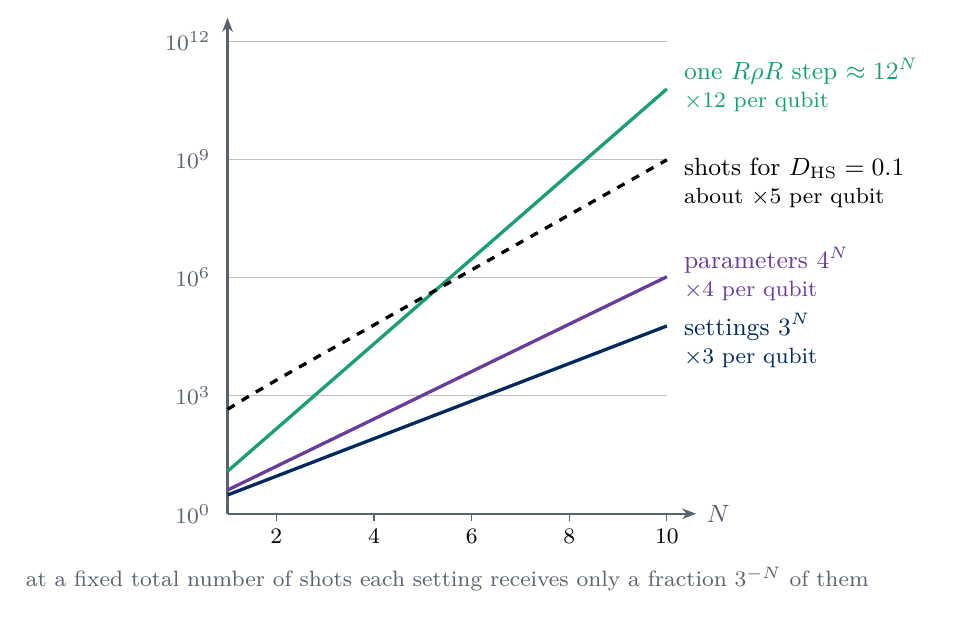

*Resources of full tomography against the number of qubits. The settings grow by a factor three per qubit and the parameters by four. One $R\rho R$ step costs about $3^N\cdot4^N=12^N$ operations, a factor twelve per qubit, of which the matrix products alone account for $8^N$. At a fixed total number of shots each setting receives a fraction $3^{-N}$ of them.*

N = 1: simulated E D_HS^2 = 0.01467, equation (20) = 0.01500, control without 3^(N-k) = 0.01500
N = 2: simulated E D_HS^2 = 0.02736, equation (20) = 0.02750, control without 3^(N-k) = 0.03750
N = 3: simulated E D_HS^2 = 0.04690, equation (20) = 0.04625, control without 3^(N-k) = 0.07875

  N   settings 3^N  parameters 4^N-1  memory of rho  R rho R step 3^N 4^N  total shots, E D_HS^2=0.01
  1              3                 3           64 B                    12                         450
  2              9                15          256 B                   144                    2.47e+03
  3             27                63     1.02e+03 B              1.73e+03                    1.25e+04
  4             81               255      4.1e+03 B              2.07e+04                    6.25e+04
  6            729           4.1e+03     6.55e+04 B              2.99e+06                    1.56e+06
  8       6.56e+03          6.55e+04     1.05e+06 B               4.3e+08                    3.91e+

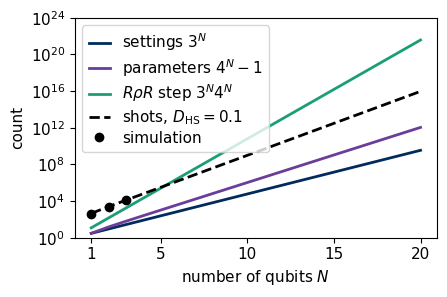

In [13]:
def li_mixed_error(n, shots, reps, key):
    # simulated E D_HS^2 of linear inversion for the maximally mixed state of n qubits
    dim = 2 ** n
    labs = pauli_labels(n)
    k_w = np.array([sum(c != "I" for c in lab) for lab in labs])   # weights k
    sets = ["".join(s) for s in itertools.product("XYZ", repeat=n)]
    sign = np.array([[(-1) ** sum(bq for bq, c in zip(bits_of(b, n), lab) if c != "I") for b in range(dim)] for lab in labs])
    compat = np.array([[all(c == "I" or c == sc for c, sc in zip(lab, s)) for s in sets] for lab in labs], dtype=float)
    probs = jnp.full((len(sets), dim), 1.0 / dim)
    counts = np.asarray(sample_many(jax.random.split(key, reps), probs, shots))           # (reps, 3^n, 2^n)
    parity_means = np.einsum("pb,rsb->rps", sign, counts / shots)                         # parity of P in setting s
    r = (parity_means * compat).sum(axis=-1) / 3.0 ** (n - k_w)                             # equation (11)
    return np.mean(np.sum(r[:, 1:] ** 2, axis=1) / dim)

M_WALL, R_WALL = 100, 400
wall = []
for n in (1, 2, 3):
    key, k = jax.random.split(key)
    sim = li_mixed_error(n, M_WALL, R_WALL, k)
    pred = (10 ** n - 1) / (6 ** n * M_WALL)
    wrong = (4 ** n - 1) / (2 ** n * M_WALL)                     # control: factor 3^(N-k) ignored
    wall.append(dict(N=n, simulated=float(sim), equation_20=pred, control=wrong))
    print(f"N = {n}: simulated E D_HS^2 = {sim:.5f}, equation (20) = {pred:.5f}, control without 3^(N-k) = {wrong:.5f}")
    assert abs(sim / pred - 1) < 0.1
    if n > 1:                                                    # at N = 1 the two counts coincide
        assert abs(sim / wrong - 1) > 0.15
print(f"\n{'N':>3s} {'settings 3^N':>14s} {'parameters 4^N-1':>17s} {'memory of rho':>14s} {'R rho R step 3^N 4^N':>21s} {'total shots, E D_HS^2=0.01':>27s}")
eps_target = 0.1
for n in (1, 2, 3, 4, 6, 8, 10, 20, 50):
    shots_needed = 3.0 ** n * (10.0 ** n - 1) / (6.0 ** n * eps_target ** 2)
    print(f"{n:3d} {3.0 ** n:14.3g} {4.0 ** n - 1:17.3g} {16 * 4.0 ** n:12.3g} B {12.0 ** n:21.3g} {shots_needed:27.3g}")
NUMBERS.update(ShotsTenQubits=sci(3.0 ** 10 * (10.0 ** 10 - 1) / (6.0 ** 10 * eps_target ** 2), 0))

ns = np.arange(1, 21)
def cost_panel(ax):
    ax.semilogy(ns, 3.0 ** ns, color=COL["navy"], lw=2, label=r"settings $3^N$")
    ax.semilogy(ns, 4.0 ** ns - 1, color=COL["purple"], lw=2, label=r"parameters $4^N-1$")
    ax.semilogy(ns, 12.0 ** ns, color=COL["teal"], lw=2, label=r"$R\rho R$ step $3^N4^N$")
    ax.semilogy(ns, 3.0 ** ns * (10.0 ** ns - 1) / (6.0 ** ns * eps_target ** 2), color=COL["exact"], lw=2, ls="--", label=r"shots, $D_{\mathrm{HS}}=0.1$")
    ax.semilogy([w_["N"] for w_ in wall], [3.0 ** w_["N"] * M_WALL * w_["simulated"] / eps_target ** 2 for w_ in wall], "o", color=COL["exact"], ms=6, label="simulation")
    ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel("count"); ax.set_xticks([1, 5, 10, 15, 20]); ax.set_ylim(1, 1e24)
    ax.legend(loc="upper left", handlelength=1.4, labelspacing=0.25)
single("fig_lab074_cost_wall", cost_panel)

The simulated errors agree with equation (20) for one, two and three qubits. The control coincides with equation (20) for one qubit, where every string has weight one, and disagrees with the simulation for two and three qubits. The figure shows that the number of shots for a fixed accuracy grows faster than the settings and the parameters, and only the classical processing of an $R\rho R$ step grows faster still. Ten qubits already need about $10^9$ shots, and fifty qubits are out of reach of any experiment. Full tomography is therefore limited to a few qubits. Larger systems need assumptions about the state, such as low rank in compressed sensing [17], or a smaller goal, such as predicting selected properties without reconstructing the full state, which randomised measurements achieve with a cost independent of $N$ for local properties [18].

The last cell stores the numbers of this lab as LaTeX macros and a JSON summary and prints the runtime.

## 12. Exercises

1. Derive the variance in equation (6) from the probability $(1-r_P)/2$ of bit 1, and show that the variance in equation (11) follows when $3^{N-k}$ settings contribute.
2. Repeat the one-qubit experiment of Section 3 for the pure state with $\boldsymbol r=(1,1,1)/\sqrt3$ and several values of $M$. Explain why the fraction of estimates outside the Bloch ball approaches one half as $M$ grows and why it exceeds one half at small $M$.
3. Prove that the projection (13) does not change the eigenvectors, by showing that $\|\tilde\rho_{\mathrm{LI}}-\hat\sigma\|_{\mathrm{HS}}$ is minimised, for fixed eigenvalues of $\hat\sigma$, when $\hat\sigma$ is diagonal in the eigenbasis of $\tilde\rho_{\mathrm{LI}}$. This exercise is optional. Use von Neumann's trace inequality, $\mathrm{Tr}(\hat A\hat B)\le\sum_ia_ib_i$ for Hermitian matrices with eigenvalues $a_1\ge\dots\ge a_d$ and $b_1\ge\dots\ge b_d$, with equality when both are diagonal in one basis with the same ordering.
4. Run the $R\rho R$ iteration on the Bell data of Section 5 and on the same data with all counts multiplied by ten. Compare the maximum-likelihood estimates and explain the result with equation (16).
5. Run the Cholesky optimisation of Section 9 on a data set of the Bell state, whose maximum-likelihood estimate lies on the boundary, and plot the smallest eigenvalue of $\hat\rho(C)$ against the gradient step. Explain which entries of the Cholesky factor $C$ must vanish at the boundary. The function `cholesky_mle` records only the loss, so let its inner function `step` return the pair `(L, jnp.linalg.eigvalsh(rho_of_params(x))[0])` as the recorded value, and `jax.lax.scan` then returns both histories.
6. Allocate the budget unevenly, with twice as many shots for the settings $XX$, $YY$ and $ZZ$, and compare linear inversion with weighted least squares for the Bell and Werner states. The function `sample_counts` takes one number of shots for all settings, so call it once with $2M$ and once with $M$ and take the rows of the three settings from the first result and the other six from the second. The function `linear_inversion` divides every setting by its own total, and `weighted_least_squares` accepts an array with the nine numbers of shots.
7. Use equation (20) to find the number of shots per setting that gives $\mathbb E\,D_{\mathrm{HS}}^2=10^{-3}$ for $N=3$, and check the answer with the function of Section 11.

## 13. Summary

A density matrix of $N$ qubits is fixed by the $4^N-1$ expectation values of the Pauli strings, and rotating every qubit into one of three bases before the measurement gives all of them from $3^N$ settings. The probabilities of the outcomes are linear in these expectation values, so the density matrix follows from the frequencies by linear inversion, which for Pauli settings is the least-squares solution and an average of parities over the settings that measure each string. Its error decreases as $M^{-1/2}$ with the number of shots per setting. The estimate ignores positivity, and for nearly pure states it has a negative eigenvalue in almost every data set. The projection of Smolin, Gambetta and Smith repairs this by shifting and clipping the eigenvalues, and it never increases the Hilbert–Schmidt distance to the true state. Maximum likelihood searches among physical states for the one that best explains the counts, either by the $R\rho R$ iteration or by gradient descent on the Cholesky factor $C$, and both give the same estimate. For the Bell state, an eigenstate of three of the measured settings, the infidelity of the maximum-likelihood estimate decreases as $M^{-1}$. For Haar-random pure states measured with the same settings it decreases with the fitted slope $-0.53$, close to the $M^{-1/2}$ of the projected estimate. The cost of tomography grows as $3^N$ in settings, $4^N$ in parameters and about $5^N$ in shots at fixed accuracy, which limits full reconstruction to a few qubits.

## References

[1] K. Vogel and H. Risken, Determination of quasiprobability distributions in terms of probability distributions for the rotated quadrature phase, Phys. Rev. A **40**, 2847 (1989), doi:[10.1103/PhysRevA.40.2847](https://doi.org/10.1103/PhysRevA.40.2847).

[2] D. F. V. James, P. G. Kwiat, W. J. Munro and A. G. White, Measurement of qubits, Phys. Rev. A **64**, 052312 (2001), doi:[10.1103/PhysRevA.64.052312](https://doi.org/10.1103/PhysRevA.64.052312).

[3] R. F. Werner, Quantum states with Einstein-Podolsky-Rosen correlations admitting a hidden-variable model, Phys. Rev. A **40**, 4277 (1989), doi:[10.1103/PhysRevA.40.4277](https://doi.org/10.1103/PhysRevA.40.4277).

[4] A. Peres, Separability criterion for density matrices, Phys. Rev. Lett. **77**, 1413 (1996), doi:[10.1103/PhysRevLett.77.1413](https://doi.org/10.1103/PhysRevLett.77.1413).

[5] M. Horodecki, P. Horodecki and R. Horodecki, Separability of mixed states: necessary and sufficient conditions, Phys. Lett. A **223**, 1 (1996), doi:[10.1016/S0375-9601(96)00706-2](https://doi.org/10.1016/S0375-9601(96)00706-2).

[6] K. Życzkowski and H.-J. Sommers, Induced measures in the space of mixed quantum states, J. Phys. A **34**, 7111 (2001), doi:[10.1088/0305-4470/34/35/335](https://doi.org/10.1088/0305-4470/34/35/335).

[7] A. Uhlmann, The "transition probability" in the state space of a *-algebra, Rep. Math. Phys. **9**, 273 (1976), doi:[10.1016/0034-4877(76)90060-4](https://doi.org/10.1016/0034-4877(76)90060-4).

[8] R. Jozsa, Fidelity for mixed quantum states, J. Mod. Opt. **41**, 2315 (1994), doi:[10.1080/09500349414552171](https://doi.org/10.1080/09500349414552171).

[9] M. A. Nielsen and I. L. Chuang, Quantum Computation and Quantum Information (Cambridge University Press, 2010), doi:[10.1017/CBO9780511976667](https://doi.org/10.1017/CBO9780511976667).

[10] K. Pearson, On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling, Phil. Mag. **50**, 157 (1900), doi:[10.1080/14786440009463897](https://doi.org/10.1080/14786440009463897).

[11] J. A. Smolin, J. M. Gambetta and G. Smith, Efficient method for computing the maximum-likelihood quantum state from measurements with additive Gaussian noise, Phys. Rev. Lett. **108**, 070502 (2012), doi:[10.1103/PhysRevLett.108.070502](https://doi.org/10.1103/PhysRevLett.108.070502).

[12] Z. Hradil, Quantum-state estimation, Phys. Rev. A **55**, R1561 (1997), doi:[10.1103/PhysRevA.55.R1561](https://doi.org/10.1103/PhysRevA.55.R1561).

[13] J. Řeháček, Z. Hradil, E. Knill and A. I. Lvovsky, Diluted maximum-likelihood algorithm for quantum tomography, Phys. Rev. A **75**, 042108 (2007), doi:[10.1103/PhysRevA.75.042108](https://doi.org/10.1103/PhysRevA.75.042108).

[14] K. Banaszek, G. M. D'Ariano, M. G. A. Paris and M. F. Sacchi, Maximum-likelihood estimation of the density matrix, Phys. Rev. A **61**, 010304 (1999), doi:[10.1103/PhysRevA.61.010304](https://doi.org/10.1103/PhysRevA.61.010304).

[15] J. Bradbury, R. Frostig, P. Hawkins, M. J. Johnson, C. Leary, D. Maclaurin, G. Necula, A. Paszke, J. VanderPlas, S. Wanderman-Milne and Q. Zhang, JAX: composable transformations of Python+NumPy programs (2018), [github.com/jax-ml/jax](https://github.com/jax-ml/jax).

[16] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), [arxiv.org/abs/1412.6980](https://arxiv.org/abs/1412.6980).

[17] D. Gross, Y.-K. Liu, S. T. Flammia, S. Becker and J. Eisert, Quantum state tomography via compressed sensing, Phys. Rev. Lett. **105**, 150401 (2010), doi:[10.1103/PhysRevLett.105.150401](https://doi.org/10.1103/PhysRevLett.105.150401).

[18] H.-Y. Huang, R. Kueng and J. Preskill, Predicting many properties of a quantum system from very few measurements, Nat. Phys. **16**, 1050 (2020), doi:[10.1038/s41567-020-0932-7](https://doi.org/10.1038/s41567-020-0932-7).